## K-Means Clustering sur 10 meilleurs descripteurs de LDA

### Import des bibliothèques

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.exceptions import ConvergenceWarning
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# Configuration matplotlib
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['figure.figsize'] = (14, 8)

### Charger dataset

In [2]:
# Charger les données nettoyées
X_train = pd.read_csv('Données/X_train_clean.csv')
print(f'Shape du dataset: {X_train.shape}')

Shape du dataset: (444, 34)


In [3]:
# Vérification des données
print(f'\nValeurs manquantes:\n{X_train.isnull().sum().sum()} valeurs manquantes au total')
print(f'\nTypes des colonnes:\n{X_train.dtypes.value_counts()}')


Valeurs manquantes:
0 valeurs manquantes au total

Types des colonnes:
float64    22
bool        9
int64       3
Name: count, dtype: int64


In [ ]:
# faire distribution des descripteurs en plot



### Preprocessing

In [4]:
# Récupérer les variables numériques et les stocker dans une liste
num_cols = X_train.select_dtypes(include=['float64', 'int64']).columns
X_num = X_train[num_cols]

numeric_cols = X_num.columns.tolist()
print(f"Colonnes numériques : {numeric_cols}")

Colonnes numériques : ['Family_Size', 'PPI_Intersection', 'PPI_Union', 'PPI_Jaccard', 'Pfam_Inter', 'Pfam_Union', 'Pfam_Jaccard', 'Ks', 'Ka', 'Ka_Ks', 'Ks_SD', 'Ka_SD', 'Distance', 'TE_Coverage_Asymmetry', 'TE_Coverage_Mean', 'TE_Number_Asymmetry', 'TE_Number_Mean', 'PPI_Interactant_Asymmetry', 'PPI_Interactant_Mean', 'Pfam_Asymmetry', 'Pfam_Mean', 'TE_Density_Asymmetry', 'TE_Density_Mean', 'TE_Env_Match', 'Expression_Data_Missing']


Variables catégorielles (12) : ['TE_Env_Pair_TE-free_TE-free', 'TE_Env_Pair_TE-free_TE-poor', 'TE_Env_Pair_TE-free_TE-rich', 'TE_Env_Pair_TE-poor_TE-poor', 'TE_Env_Pair_TE-poor_TE-rich', 'TE_Env_Pair_TE-rich_TE-rich', 'TE_Env_Class_free', 'TE_Env_Class_half', 'TE_Env_Class_rich', 'Pfam_Asymmetry', 'TE_Env_Match', 'Expression_Data_Missing']
Variables continues (22) : ['Family_Size', 'PPI_Intersection', 'PPI_Union', 'PPI_Jaccard', 'Pfam_Inter', 'Pfam_Union', 'Pfam_Jaccard', 'Ks', 'Ka', 'Ka_Ks', 'Ks_SD', 'Ka_SD', 'Distance', 'TE_Coverage_Asymmetry', 'TE_Coverage_Mean', 'TE_Number_Asymmetry', 'TE_Number_Mean', 'PPI_Interactant_Asymmetry', 'PPI_Interactant_Mean', 'Pfam_Mean', 'TE_Density_Asymmetry', 'TE_Density_Mean']


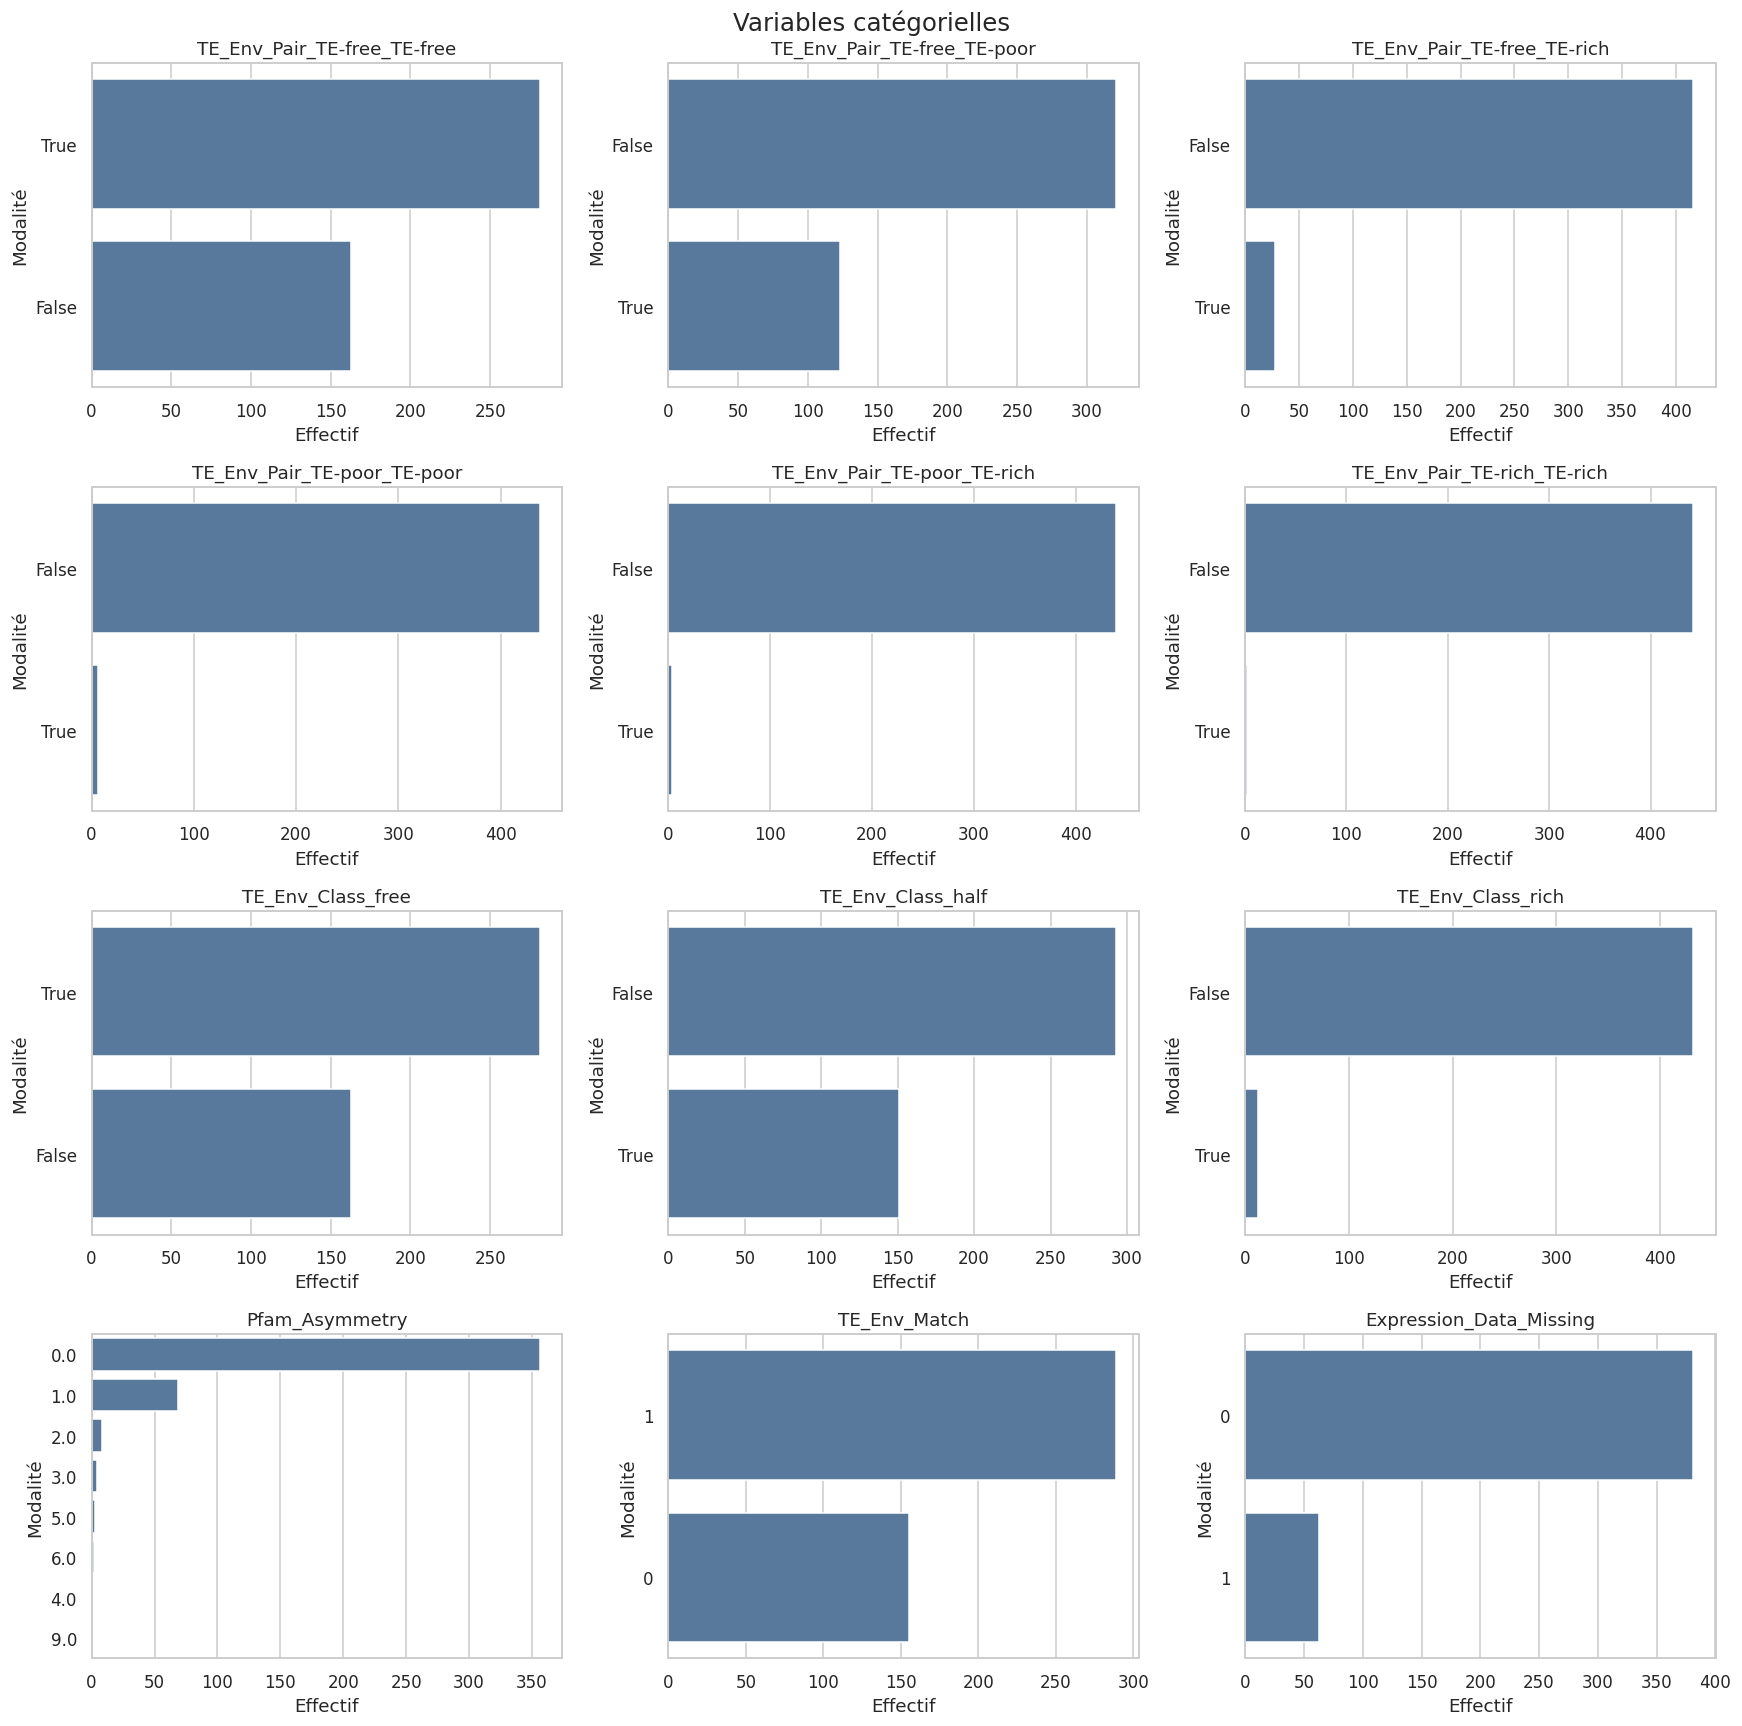

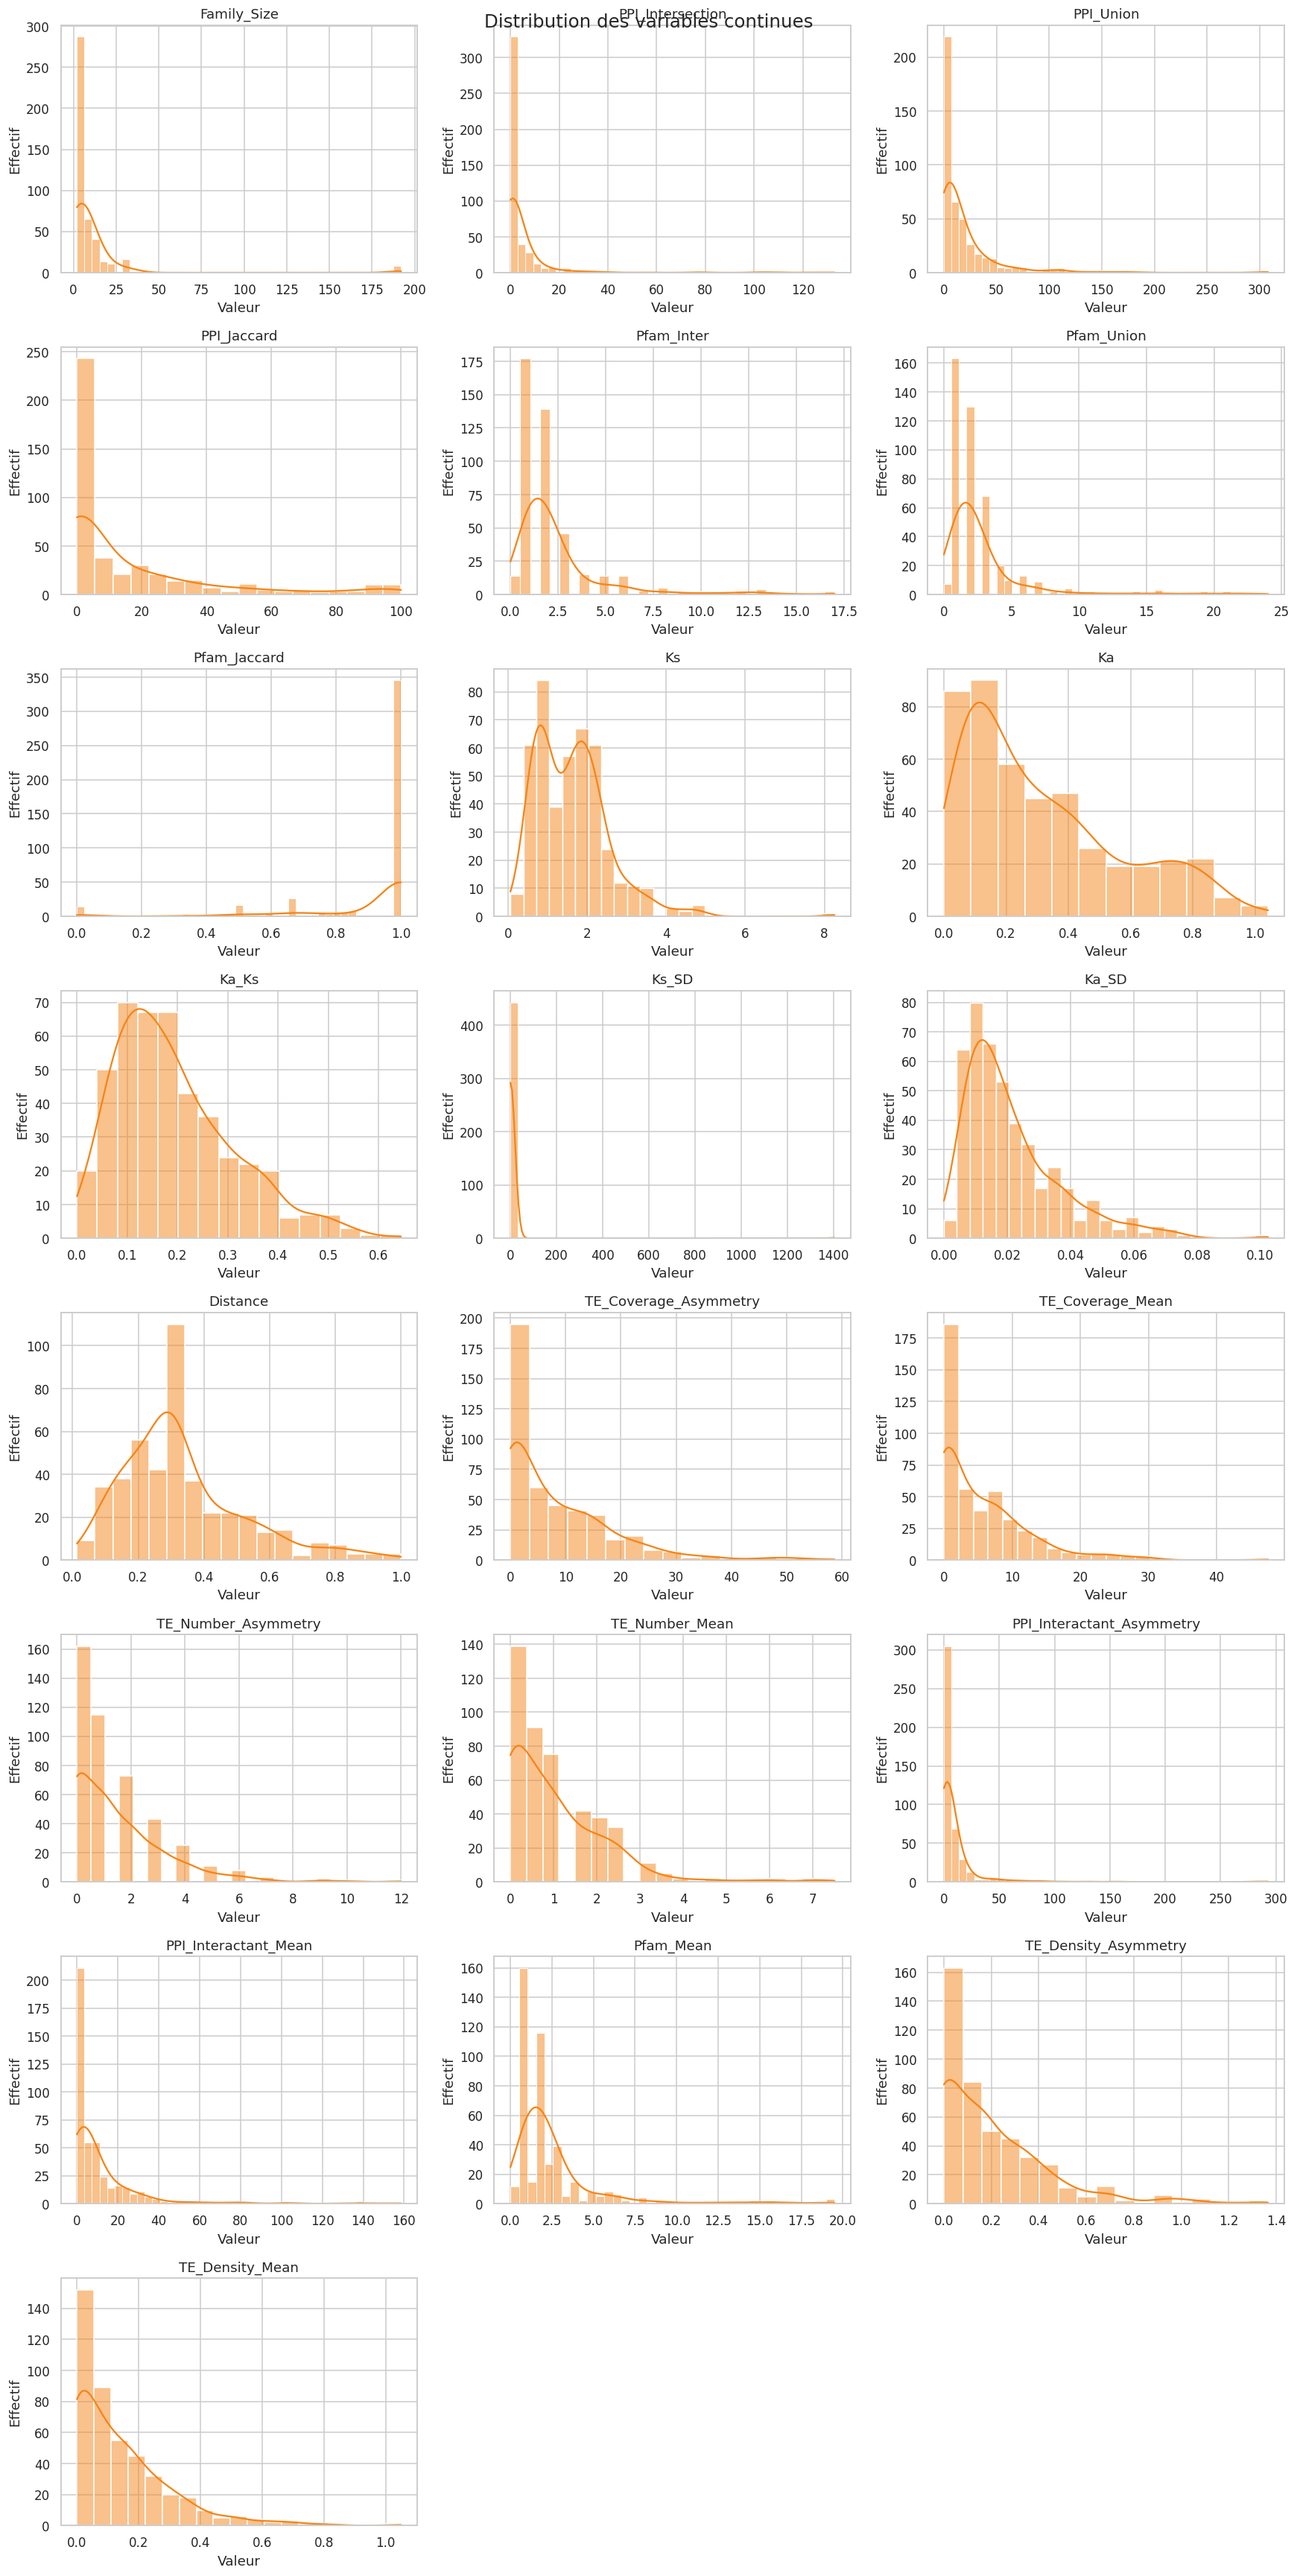

In [5]:
# Distribution des variables catégorielles et continues de X_train
max_categories = 10
categorical_cols = X_train.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()
numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()
encoded_categorical_cols = [
    column for column in numeric_cols
    if X_train[column].nunique(dropna=True) <= max_categories
]
categorical_cols = list(dict.fromkeys(categorical_cols + encoded_categorical_cols))
continuous_cols = [column for column in numeric_cols if column not in categorical_cols]

print(f"Variables catégorielles ({len(categorical_cols)}) : {categorical_cols}")
print(f"Variables continues ({len(continuous_cols)}) : {continuous_cols}")

if categorical_cols:
    n_columns = 3
    n_rows = int(np.ceil(len(categorical_cols) / n_columns))
    fig, axes = plt.subplots(n_rows, n_columns, figsize=(16, 4 * n_rows))
    axes = np.atleast_1d(axes).ravel()

    for axis, column in zip(axes, categorical_cols):
        counts = X_train[column].astype('object').fillna('Valeur manquante').value_counts().head(20)
        sns.barplot(x=counts.values, y=counts.index.astype(str), ax=axis, color='#4C78A8')
        axis.set_title(column)
        axis.set_xlabel('Effectif')
        axis.set_ylabel('Modalité')

    for axis in axes[len(categorical_cols):]:
        axis.remove()
    fig.suptitle('Variables catégorielles', fontsize=16)
    fig.tight_layout()
    plt.show()

if continuous_cols:
    n_columns = 3
    n_rows = int(np.ceil(len(continuous_cols) / n_columns))
    fig, axes = plt.subplots(n_rows, n_columns, figsize=(16, 4 * n_rows))
    axes = np.atleast_1d(axes).ravel()

    for axis, column in zip(axes, continuous_cols):
        sns.histplot(data=X_train, x=column, kde=True, ax=axis, color='#F58518')
        axis.set_title(column)
        axis.set_xlabel('Valeur')
        axis.set_ylabel('Effectif')

    for axis in axes[len(continuous_cols):]:
        axis.remove()
    fig.suptitle('Distribution des variables continues', fontsize=16)
    fig.tight_layout()
    plt.show()


In [6]:
print(X_train['Expression_Data_Missing'].value_counts())

Expression_Data_Missing
0    381
1     63
Name: count, dtype: int64


In [7]:
print(X_train['TE_Number_Asymmetry'].value_counts())

TE_Number_Asymmetry
0.0     162
1.0     115
2.0      73
3.0      43
4.0      25
5.0      11
6.0       8
7.0       3
9.0       2
10.0      1
12.0      1
Name: count, dtype: int64


In [8]:
# pour les missing_indices, print les valeurs de la colonne 'Distance' avant l'imputation utilisant X_train et pas X_train.loc[missing_indices, 'Distance'] pour éviter les SettingWithCopyWarning
# print(f"Valeurs Distances avant: {X_train['Distance'].iloc[missing_indices]}")

In [9]:
# # Récupérer les indices des lignes où 'Expression_Data_Missing' est égal à 1
# missing_indices = X_train[X_train['Expression_Data_Missing'] == 1].index
# print(f"Indices des lignes avec Expression_Data_Missing = 1 : {missing_indices}")
# # imputer les valeurs manquantes avec la médiane pour la colonne 'Distance' au niveau des missing_indices
# median_distance = X_train['Distance'].median()
# print(f"Médiane de la colonne 'Distance' : {median_distance}")
# X_train.loc[missing_indices, 'Distance'] = X_train.loc[missing_indices, 'Distance'].fillna(median_distance)
# print(f"Valeurs Distances après: {X_train.loc[missing_indices, 'Distance']}")

In [10]:
# Recharger les données originales pour supprimer les anciennes valeurs infinies
X_train = pd.read_csv("Données/X_train_clean.csv")

# Sélectionner les variables TE
te_cols = [
    column for column in X_train.columns
    if column.startswith("TE_")
]

# Convertir en numérique
te_data = X_train[te_cols].apply(pd.to_numeric, errors="coerce")

# Les valeurs manquantes sont considérées comme des zéros structurels
te_data = te_data.fillna(0.0)

# Ensure all TE columns use a homogeneous floating-point dtype.
# This is necessary because Boolean columns otherwise produce an object array.
te_data = te_data.astype(np.float64)

non_finite_mask = ~np.isfinite(te_data.to_numpy())

if non_finite_mask.any():
    invalid_columns = te_data.columns[
        non_finite_mask.any(axis=0)
    ].tolist()
    raise ValueError(
        f"Les variables TE contiennent des valeurs infinies ou non finies : "
        f"{invalid_columns}"
    )

if (te_data < 0).any().any():
    raise ValueError(
        "La transformation CLR nécessite des valeurs positives ou nulles."
    )

# Récupérer uniquement les valeurs strictement positives
positive_values = te_data.to_numpy()
positive_values = positive_values[positive_values > 0]

if positive_values.size == 0:
    raise ValueError(
        "Toutes les valeurs des variables TE sont nulles."
    )

# Pseudo-compte strictement positif
pseudocount = max(
    positive_values.min() / 2,
    np.finfo(float).eps
)

# Remplacer les zéros par le pseudo-compte
te_data_positive = te_data.mask(
    te_data <= 0,
    pseudocount
)

# Vérification avant logarithme
if (te_data_positive <= 0).any().any():
    raise ValueError(
        "Des valeurs nulles ou négatives persistent avant le logarithme."
    )

# Transformation CLR
log_te_data = np.log(te_data_positive)
log_geometric_mean = log_te_data.mean(axis=1)
te_data_clr = log_te_data.subtract(log_geometric_mean, axis=0)

# Remplacer les variables TE originales
X_train[te_cols] = te_data_clr

# Mettre à jour X_num
if "X_num" in globals():
    common_te_cols = [
        column for column in te_cols
        if column in X_num.columns
    ]
    X_num[common_te_cols] = X_train[common_te_cols]

# Vérifications finales
print("Pseudo-compte utilisé :", pseudocount)
print("Présence de valeurs infinies :", np.isinf(X_train[te_cols].to_numpy()).any())
print("Présence de NaN :", X_train[te_cols].isna().any().any())
print("Somme CLR moyenne par ligne :", X_train[te_cols].sum(axis=1).mean())

print("\nRésumé après transformation CLR :")
print(X_train[te_cols].describe())

Pseudo-compte utilisé : 0.00077929017981785
Présence de valeurs infinies : False
Présence de NaN : False
Somme CLR moyenne par ligne : -7.966600352377813e-15

Résumé après transformation CLR :
       TE_Coverage_Asymmetry  TE_Coverage_Mean  TE_Number_Asymmetry  \
count             444.000000        444.000000           444.000000   
mean                3.304344          3.052285             1.893930   
std                 3.234128          3.065127             2.732784   
min                -1.341961         -1.341961            -3.555339   
25%                -1.341961         -1.341961            -1.341961   
50%                 4.895789          4.441272             3.367169   
75%                 5.979880          5.550807             4.098299   
max                 7.000952          7.032812             5.388752   

       TE_Number_Mean  TE_Density_Asymmetry  TE_Density_Mean  TE_Env_Match  \
count      444.000000            444.000000       444.000000    444.000000   
mean       

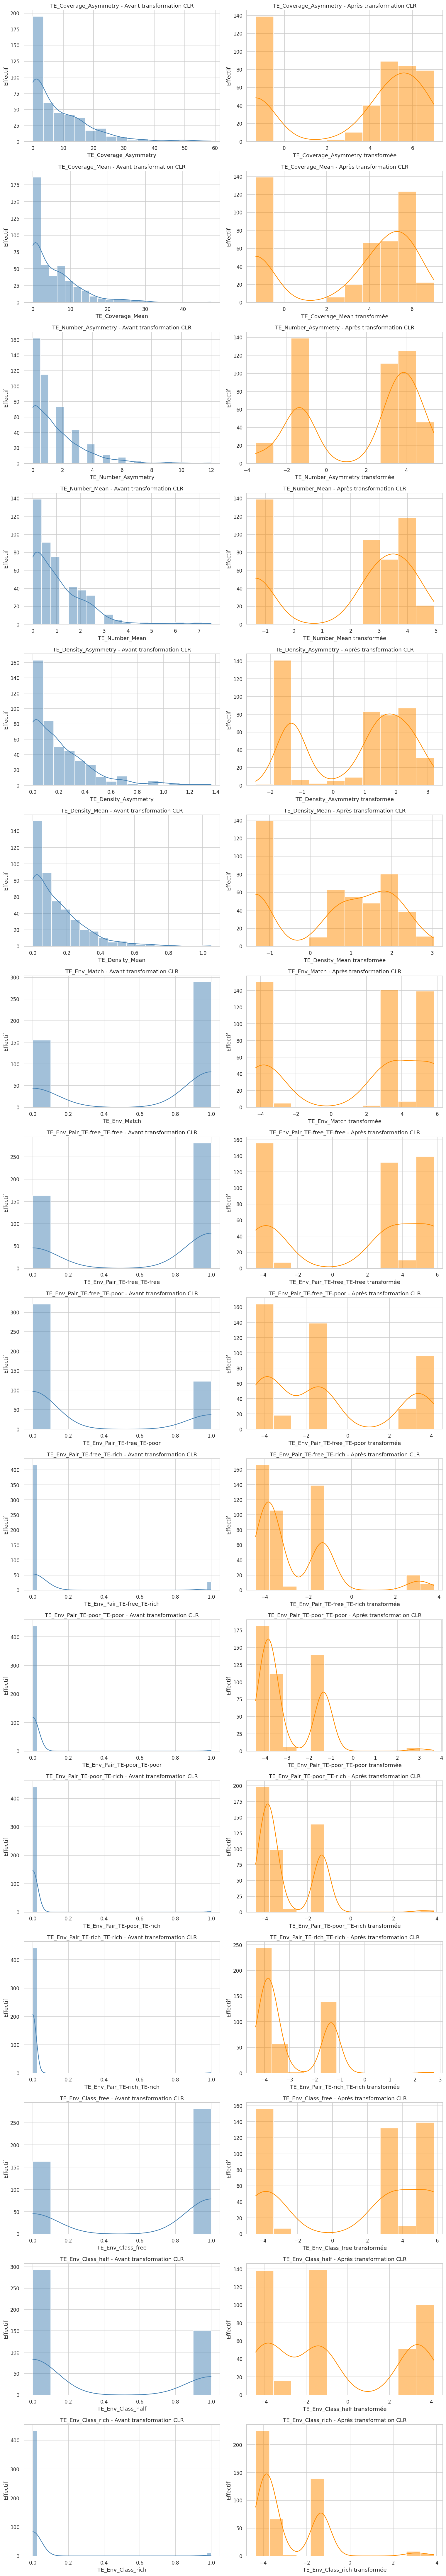

In [11]:
# Recharger les données originales pour conserver les valeurs avant CLR
X_train_before_clr = pd.read_csv("Données/X_train_clean.csv")

# Sélectionner les variables TE
te_cols = [
    column for column in X_train_before_clr.columns
    if column.startswith("TE_")
]

# Données avant et après transformation CLR
te_data_before = X_train_before_clr[te_cols]
te_data_after = X_train[te_cols]

# Créer une ligne de graphiques par variable TE
fig, axes = plt.subplots(
    nrows=len(te_cols),
    ncols=2,
    figsize=(14, 5 * len(te_cols))
)

# Cas particulier s'il n'y a qu'une seule variable TE
if len(te_cols) == 1:
    axes = np.array([axes])

for index, column in enumerate(te_cols):
    # Distribution avant CLR
    sns.histplot(
        te_data_before[column].dropna(),
        kde=te_data_before[column].nunique() > 1,
        ax=axes[index, 0],
        color="steelblue"
    )
    axes[index, 0].set_title(f"{column} - Avant transformation CLR")
    axes[index, 0].set_xlabel(column)
    axes[index, 0].set_ylabel("Effectif")

    # Distribution après CLR
    sns.histplot(
        te_data_after[column].dropna(),
        kde=te_data_after[column].nunique() > 1,
        ax=axes[index, 1],
        color="darkorange"
    )
    axes[index, 1].set_title(f"{column} - Après transformation CLR")
    axes[index, 1].set_xlabel(f"{column} transformée")
    axes[index, 1].set_ylabel("Effectif")

plt.tight_layout()
plt.show()

## Linear Discriminant Analysis

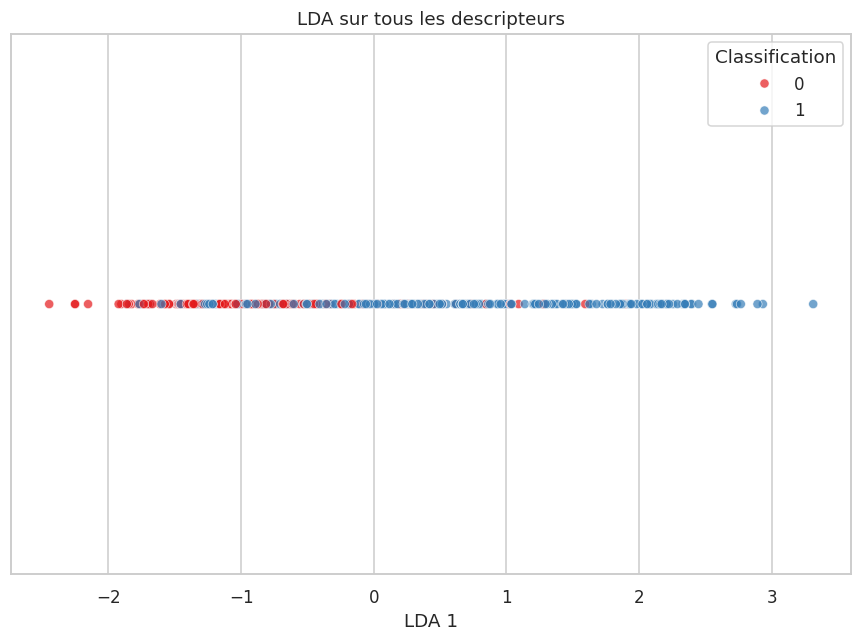

Shape après LDA : (444, 1)


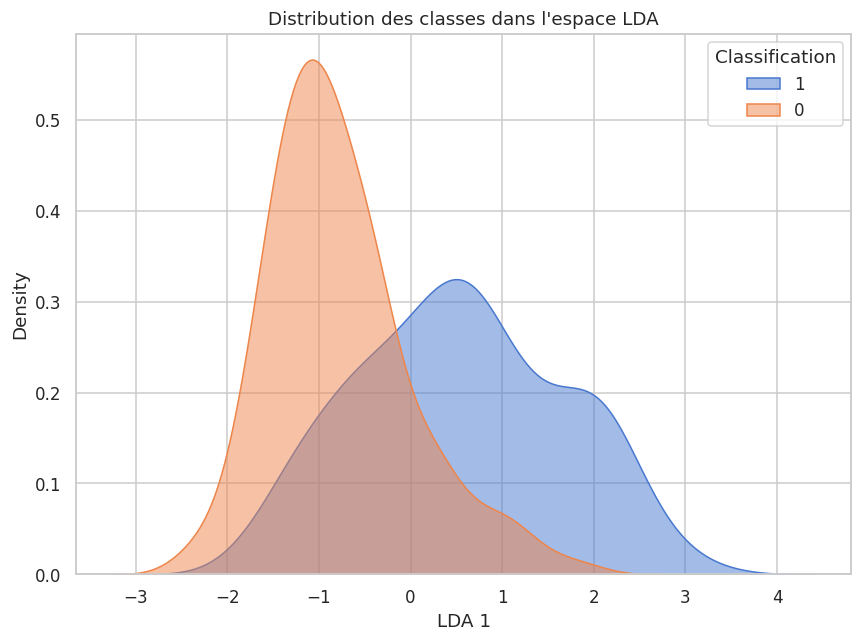

In [12]:
# LDA sur tous les descripteurs numériques

y_train = pd.read_csv("Données/Y_train_clean.csv")
# aligner y_train avec les lignes des descripteurs numériques
if y_train.shape[0] != X_num.shape[0]:
    y_train = y_train.reindex(X_num.index).reset_index(drop=True)
else:
    y_train = y_train.reset_index(drop=True)

X_num = X_num.drop(columns=['Ka_SD', 'Ks_SD','Expression_Data_Missing'])

X_all = X_num.copy()
scaler = StandardScaler()
X_all_scaled = scaler.fit_transform(X_all)

n_components = min(2, len(y_train['Classification'].dropna().unique()) - 1)
lda = LinearDiscriminantAnalysis(n_components=n_components)
X_lda = lda.fit_transform(X_all_scaled, y_train['Classification'])

if n_components == 1:
    df_lda = pd.DataFrame({'LDA_1': X_lda[:, 0], 'Classification': y_train['Classification']})
else:
    df_lda = pd.DataFrame(X_lda, columns=['LDA_1', 'LDA_2'])
    df_lda['Classification'] = y_train['Classification']

plt.figure(figsize=(8, 6))
if n_components == 1:
    sns.scatterplot(data=df_lda, x='LDA_1', y=np.zeros(len(df_lda)), hue='Classification', palette='Set1', alpha=0.7)
    plt.ylabel('')
    plt.yticks([])
else:
    sns.scatterplot(data=df_lda, x='LDA_1', y='LDA_2', hue='Classification', palette='Set1', alpha=0.7)
plt.title('LDA sur tous les descripteurs')
plt.xlabel('LDA 1')
plt.tight_layout()
plt.savefig('Plots/t_SNE_family/lda_all_descriptors.png', dpi=300, bbox_inches='tight')
plt.show()

print("Shape après LDA :", X_lda.shape)

# fais un kde plot pour visualiser la distribution des classes dans l'espace LDA
plt.figure(figsize=(8, 6))
if n_components == 1:
    for cls in df_lda['Classification'].unique():
        sns.kdeplot(df_lda[df_lda['Classification'] == cls]['LDA_1'], label=cls, fill=True, alpha=0.5)
    plt.xlabel('LDA 1')
else:
    for cls in df_lda['Classification'].unique():
        sns.kdeplot(
            x=df_lda[df_lda['Classification'] == cls]['LDA_1'],
            y=df_lda[df_lda['Classification'] == cls]['LDA_2'],
            label=cls,
            fill=True,
            alpha=0.5
        )
    plt.xlabel('LDA 1')
    plt.ylabel('LDA 2')
plt.title('Distribution des classes dans l\'espace LDA')
plt.legend(title='Classification')
plt.tight_layout()
plt.savefig('Plots/kmeans/lda/lda_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

In [13]:
# Affiche un tableau avec les coefficients ordonnées par valeur absolue de LDA pour chaque descripteur
coef_df = pd.DataFrame(lda.coef_, columns=X_all.columns)
coef_df = coef_df.T
coef_df['max_abs_coef'] = coef_df.abs().max(axis=1)
coef_df_sorted = coef_df.sort_values(by='max_abs_coef', ascending=False)
coef_df_sorted.head(10)  # Affiche les 10 descripteurs les plus importants selon LDA

,0,max_abs_coef
TE_Density_Asymmetry,-1.225182,1.225182
Ka,1.190626,1.190626
TE_Number_Mean,0.771489,0.771489
TE_Number_Asymmetry,0.577910,0.577910
PPI_Jaccard,-0.415922,0.415922
TE_Coverage_Asymmetry,-0.361040,0.361040
Pfam_Union,-0.272692,0.272692
PPI_Interactant_Mean,0.265112,0.265112
PPI_Union,0.245019,0.245019
Family_Size,0.230908,0.230908


Variables catégorielles (2) : ['Pfam_Asymmetry', 'Expression_Data_Missing']
Variables continues (32) : ['Family_Size', 'PPI_Intersection', 'PPI_Union', 'PPI_Jaccard', 'Pfam_Inter', 'Pfam_Union', 'Pfam_Jaccard', 'Ks', 'Ka', 'Ka_Ks', 'Ks_SD', 'Ka_SD', 'Distance', 'TE_Coverage_Asymmetry', 'TE_Coverage_Mean', 'TE_Number_Asymmetry', 'TE_Number_Mean', 'PPI_Interactant_Asymmetry', 'PPI_Interactant_Mean', 'Pfam_Mean', 'TE_Density_Asymmetry', 'TE_Density_Mean', 'TE_Env_Match', 'TE_Env_Pair_TE-free_TE-free', 'TE_Env_Pair_TE-free_TE-poor', 'TE_Env_Pair_TE-free_TE-rich', 'TE_Env_Pair_TE-poor_TE-poor', 'TE_Env_Pair_TE-poor_TE-rich', 'TE_Env_Pair_TE-rich_TE-rich', 'TE_Env_Class_free', 'TE_Env_Class_half', 'TE_Env_Class_rich']


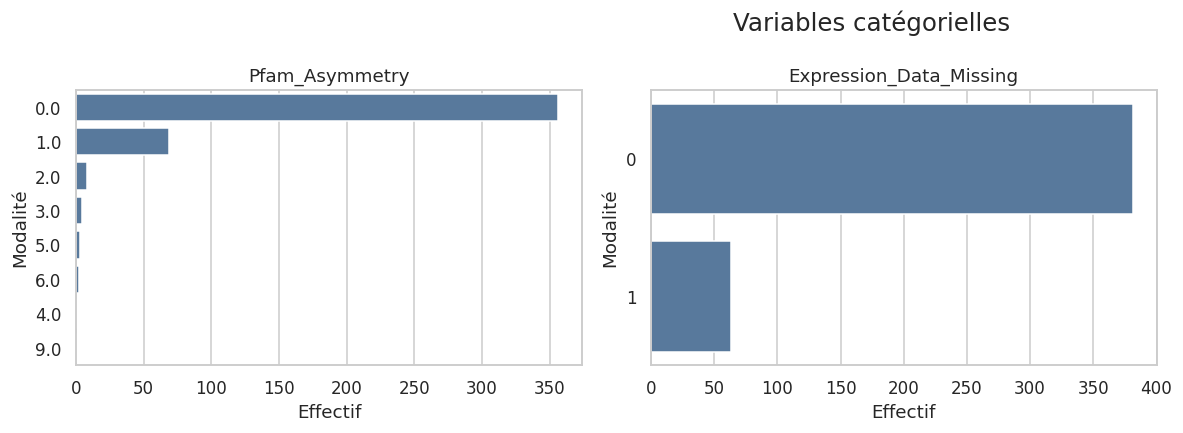

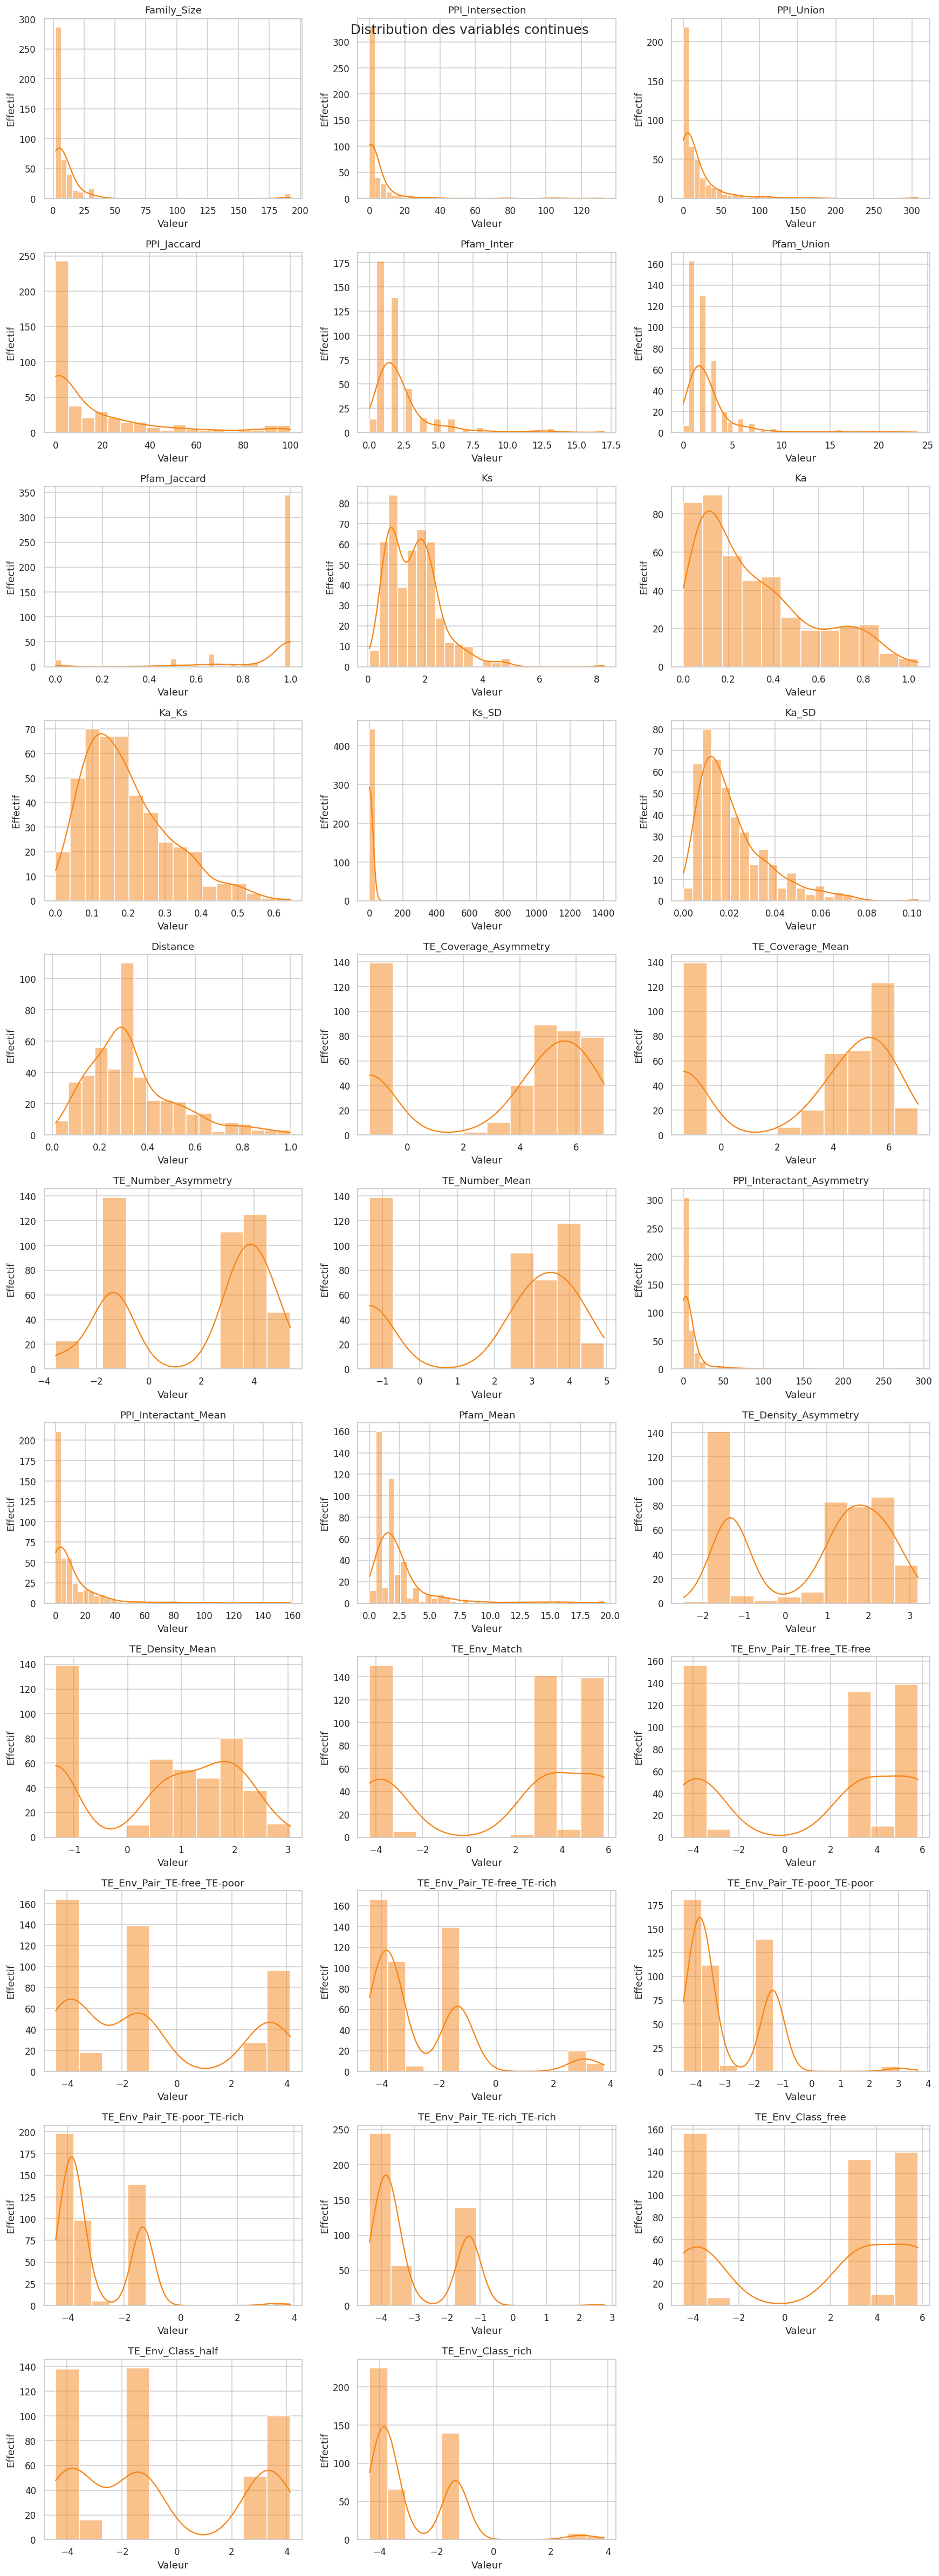

In [14]:
# Distribution des variables catégorielles et continues de X_train
max_categories = 10
categorical_cols = X_train.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()
numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()
encoded_categorical_cols = [
    column for column in numeric_cols
    if X_train[column].nunique(dropna=True) <= max_categories
]
categorical_cols = list(dict.fromkeys(categorical_cols + encoded_categorical_cols))
continuous_cols = [column for column in numeric_cols if column not in categorical_cols]

print(f"Variables catégorielles ({len(categorical_cols)}) : {categorical_cols}")
print(f"Variables continues ({len(continuous_cols)}) : {continuous_cols}")

if categorical_cols:
    n_columns = 3
    n_rows = int(np.ceil(len(categorical_cols) / n_columns))
    fig, axes = plt.subplots(n_rows, n_columns, figsize=(16, 4 * n_rows))
    axes = np.atleast_1d(axes).ravel()

    for axis, column in zip(axes, categorical_cols):
        counts = X_train[column].astype('object').fillna('Valeur manquante').value_counts().head(20)
        sns.barplot(x=counts.values, y=counts.index.astype(str), ax=axis, color='#4C78A8')
        axis.set_title(column)
        axis.set_xlabel('Effectif')
        axis.set_ylabel('Modalité')

    for axis in axes[len(categorical_cols):]:
        axis.remove()
    fig.suptitle('Variables catégorielles', fontsize=16)
    fig.tight_layout()
    plt.show()

if continuous_cols:
    n_columns = 3
    n_rows = int(np.ceil(len(continuous_cols) / n_columns))
    fig, axes = plt.subplots(n_rows, n_columns, figsize=(16, 4 * n_rows))
    axes = np.atleast_1d(axes).ravel()

    for axis, column in zip(axes, continuous_cols):
        sns.histplot(data=X_train, x=column, kde=True, ax=axis, color='#F58518')
        axis.set_title(column)
        axis.set_xlabel('Valeur')
        axis.set_ylabel('Effectif')

    for axis in axes[len(continuous_cols):]:
        axis.remove()
    fig.suptitle('Distribution des variables continues', fontsize=16)
    fig.tight_layout()
    plt.show()


## K-means sans t-SNE sur 5 meilleurs descripteurs

In [15]:
X_top_5 = X_all[coef_df_sorted.head(5).index]
scaler_top_5 = StandardScaler()
X_top_5_scaled = pd.DataFrame(scaler_top_5.fit_transform(X_top_5), columns=X_top_5.columns)


In [16]:
# Paramètres K-means
k_values = [2, 3, 4, 5, 7, 9, 10]  # Tester k = 2, 3, 4, 5, 7, 9, 10
n_init = 20
random_state = 42

# Stocker les résultats des descripteurs
kmeans_res = {}


print("Exécution du K-means sur chaque famille de descripteurs...")
print("-" * 70)

for descriptor in X_top_5_scaled.columns:
    X_descriptor = X_top_5_scaled[descriptor]
    
    # Dictionnaire pour stocker les métriques pour cette famille
    descriptor_results = {
        'inertia': [],
        'silhouette': [],
        'davies_bouldin': [],
        'calinski_harabasz': [],
        'models': [],
        'labels': []
    }
    
    for k in k_values:
        kmeans = KMeans(n_clusters=k, n_init=n_init, random_state=random_state, init='k-means++')
        labels = kmeans.fit_predict(X_descriptor.values.reshape(-1, 1))
        descriptor_results['labels'].append(labels)

        # Calculer les métriques
        inertia = kmeans.inertia_
        silhouette = silhouette_score(X_descriptor.values.reshape(-1, 1), labels) if len(np.unique(labels)) > 1 else np.nan
        davies_bouldin = davies_bouldin_score(X_descriptor.values.reshape(-1, 1), labels) if len(np.unique(labels)) > 1 else np.nan
        calinski_harabasz = calinski_harabasz_score(X_descriptor.values.reshape(-1, 1), labels) if len(np.unique(labels)) > 1 else np.nan
        
        descriptor_results['inertia'].append(inertia)
        descriptor_results['silhouette'].append(silhouette)
        descriptor_results['davies_bouldin'].append(davies_bouldin)
        descriptor_results['calinski_harabasz'].append(calinski_harabasz)
        descriptor_results['models'].append(kmeans)
    
    kmeans_res[descriptor] = descriptor_results
    print(f"{descriptor}: {X_descriptor.shape[0]} échantillons testés")

print("-" * 70)

Exécution du K-means sur chaque famille de descripteurs...
----------------------------------------------------------------------
Ka: 444 échantillons testés
TE_Density_Asymmetry: 444 échantillons testés
TE_Coverage_Asymmetry: 444 échantillons testés
PPI_Union: 444 échantillons testés
PPI_Jaccard: 444 échantillons testés
----------------------------------------------------------------------


### Critères internes de qualité

In [17]:
columns = list(X_top_5_scaled.columns)

summary_inertie = []
summary_inertie_diff = []

for k_index, k in enumerate(k_values):
    row_inertie = {}
    row_diff = {}
    
    # Remplir les inerties brutes pour ce k
    for family_name in columns:
        row_inertie[family_name] = kmeans_res[family_name]['inertia'][k_index]
    
    summary_inertie.append(row_inertie)
    
    # Calculer les différences d'inertie pour chaque famille
    for family_name in columns:
        if k_index == 0:
            row_diff[f'Diff {family_name}'] = np.nan
        else:
            previous_inertia = summary_inertie[k_index - 1][family_name]
            current_inertia = row_inertie[family_name]
            row_diff[f'Diff {family_name}'] = current_inertia - previous_inertia
    
    summary_inertie_diff.append(row_diff)

print("Valeur de l'inertie pour différents k & familles")

summary_inertie_df = pd.DataFrame(summary_inertie, index=k_values)
summary_inertie_df.index.name = 'k'
print(summary_inertie_df.to_string())

print("\nValeur de différence d'inertie pour différents k & familles")

summary_inertie_diff_df = pd.DataFrame(summary_inertie_diff, index=k_values)
summary_inertie_diff_df.index.name = 'k'
print(summary_inertie_diff_df.to_string())

Valeur de l'inertie pour différents k & familles
            Ka  TE_Density_Asymmetry  TE_Coverage_Asymmetry   PPI_Union  PPI_Jaccard
k                                                                                   
2   116.265396             46.113747              24.451503  167.086227   108.854900
3    44.814539             15.206524               7.640341   89.229348    39.678026
4    27.302563              9.468935               3.960826   42.679768    19.416252
5    18.324654              6.074513               2.696885   25.696007    11.776357
7     9.611898              3.002116               1.273547    9.394012     5.103433
9     5.816776              1.988103               0.671405    5.544317     3.064009
10    4.889703              1.620333               0.547868    4.200297     2.492825

Valeur de différence d'inertie pour différents k & familles
      Diff Ka  Diff TE_Density_Asymmetry  Diff TE_Coverage_Asymmetry  Diff PPI_Union  Diff PPI_Jaccard
k                     

In [18]:
# Calculer l’inertie pour K=1, en calculant la valeur moyenne des descripeurs et en prenant le point le plus proche de cette moyenne comme centre du cluster au sens de la distance euclidienne
def inertia_k1(X_top_5_scaled):
    inertia_k1 = []
    for family_name in X_top_5_scaled.columns:
        X_family = X_top_5_scaled[family_name]
        # Calculer la moyenne des descripteurs
        mean_descriptor = X_family.mean()
        # Trouver le point le plus proche de cette moyenne
        closest_point = X_family.iloc[(X_family - mean_descriptor).pow(2).idxmin()]
        # Calculer l’inertie pour K=1
        inertia_k1.append(((X_family - closest_point) ** 2).sum().sum())
        print(f"\nInertie pour K=1 {family_name} : {inertia_k1[-1]}") 
    return inertia_k1


In [19]:
columns = list(X_top_5_scaled.columns)

summary_silhouette = []
for k_index, k in enumerate(k_values):
    row_silhouette = {}
    
    # Remplir les silhouettes brutes pour ce k
    for family_name in columns:
        row_silhouette[family_name] = kmeans_res[family_name]['silhouette'][k_index]
    summary_silhouette.append(row_silhouette)

summary_silhouette_mean = {
    f"Moyenne {family_name}": np.mean(kmeans_res[family_name]['silhouette'])
    for family_name in columns
}
summary_silhouette_min = {
    f"Minimum  {family_name}": np.min(kmeans_res[family_name]['silhouette'])
    for family_name in columns
}
print("Valeur de la silhouette pour différents k & familles")

summary_silhouette_df = pd.DataFrame(summary_silhouette, index=k_values)
summary_silhouette_df.index.name = 'k'
print(summary_silhouette_df.to_string())

summary_silhouette_mean_df = pd.DataFrame([summary_silhouette_mean])
print("\nMoyenne du score de silhouette pour chaque famille (tous les k)")
print(summary_silhouette_mean_df.to_string(index=False))

summary_silhouette_min_df = pd.DataFrame([summary_silhouette_min])
print("\Minimum du score de silhouette pour chaque famille (tous les k)")
print(summary_silhouette_min_df.to_string(index=False))


Valeur de la silhouette pour différents k & familles
          Ka  TE_Density_Asymmetry  TE_Coverage_Asymmetry  PPI_Union  PPI_Jaccard
k                                                                                
2   0.650850              0.832791               0.888813   0.829859     0.773327
3   0.640531              0.734604               0.742664   0.744440     0.749136
4   0.601431              0.686766               0.736278   0.707596     0.750784
5   0.584779              0.706868               0.730663   0.653273     0.752741
7   0.557657              0.693793               0.687494   0.656158     0.787043
9   0.555332              0.689928               0.698196   0.604488     0.777970
10  0.557220              0.690445               0.696059   0.611936     0.774421

Moyenne du score de silhouette pour chaque famille (tous les k)
 Moyenne Ka  Moyenne TE_Density_Asymmetry  Moyenne TE_Coverage_Asymmetry  Moyenne PPI_Union  Moyenne PPI_Jaccard
   0.592543                    

### Contrôle des tailles de clusters

In [20]:
from collections import Counter
import pandas as pd

summary_tables = {}

for family_name in X_top_5_scaled.columns:

    rows = []

    for i, K in enumerate(k_values):

        labels = kmeans_res[family_name]["labels"][i]

        counts = Counter(labels)
        sizes = np.array(sorted(counts.values()))
        proportions = sizes / len(labels)

        taille_min = sizes.min()
        taille_max = sizes.max()

        prop_min = proportions.min()
        prop_max = proportions.max()

        # Critère simple de partition triviale
        acceptable = "Oui"
        if prop_max > 0.80:
            acceptable = "Non (cluster dominant)"

        rows.append({
            "K": K,
            "Taille min": taille_min,
            "Taille max": taille_max,
            "Proportion min": round(prop_min, 3),
            "Proportion max": round(prop_max, 3),
            "Acceptabilité partition": acceptable
        })

    summary_tables[family_name] = pd.DataFrame(rows)
    print(f'Tableau pour {family_name}\n')
    print(summary_tables[f'{family_name}'].to_string(index = False))


Tableau pour Ka

 K  Taille min  Taille max  Proportion min  Proportion max Acceptabilité partition
 2         138         306           0.311           0.689                     Oui
 3          81         230           0.182           0.518                     Oui
 4          73         174           0.164           0.392                     Oui
 5          41         174           0.092           0.392                     Oui
 7          33         119           0.074           0.268                     Oui
 9          11          96           0.025           0.216                     Oui
10           4         104           0.009           0.234                     Oui
Tableau pour TE_Density_Asymmetry

 K  Taille min  Taille max  Proportion min  Proportion max Acceptabilité partition
 2         153         291           0.345           0.655                     Oui
 3         133         160           0.300           0.360                     Oui
 4          84         150         

### Stabilité par sous-échantillonnage

In [21]:
# fonction de sous-échantillonnage
from sklearn.metrics import adjusted_rand_score

def run_kmeans_subsample(X_scaled, K, sample_fraction=0.8, random_state=None):
        rng = np.random.default_rng(random_state)
        n = X_scaled.shape[0]
        sample_size = int(sample_fraction * n)

        indices = rng.choice(n, size=sample_size, replace=False)
        X_sub = X_scaled.iloc[indices]  # <--- utilise iloc pour sélection des lignes
        
        model = KMeans(
            n_clusters=K,
            init='k-means++',
            n_init=20,
            random_state=random_state
        )
        labels_sub = model.fit_predict(X_sub)

        return indices, labels_sub

In [22]:
# Comparaison de deux sous-échantillons
def ari_on_common_indices(indices_1, labels_1, indices_2, labels_2, min_common=10):
    # observations communes aux deux sous-échantillons
    common = np.intersect1d(indices_1, indices_2)

    # Sécurité : si l'intersection est trop petite, l'ARI est peu informatif
    if len(common) < min_common:
        return np.nan

    # dictionnaires observation -> label
    dict_1 = {idx: lab for idx, lab in zip(indices_1, labels_1)}
    dict_2 = {idx: lab for idx, lab in zip(indices_2, labels_2)}

    # labels des mêmes observations dans les deux partitions
    common_labels_1 = [dict_1[idx] for idx in common]
    common_labels_2 = [dict_2[idx] for idx in common]

    return adjusted_rand_score(common_labels_1, common_labels_2)

In [23]:
# Boucle complète de stabilité
def stability_by_ari(X_scaled, K, n_repeats=50, sample_fraction=0.8):
    subsamples = []

    for b in range(n_repeats):
        indices, labels = run_kmeans_subsample(
            X_scaled,
            K,
            sample_fraction=sample_fraction,
            random_state=b
        )
        subsamples.append((indices, labels))

    ari_values = []

    for i in range(n_repeats):
        for j in range(i + 1, n_repeats):
            ari = ari_on_common_indices(
                subsamples[i][0], subsamples[i][1],
                subsamples[j][0], subsamples[j][1]
            )
            if not np.isnan(ari):
                ari_values.append(ari)

    return np.array(ari_values)

In [24]:
# Application à la grille de K

top_5_descriptors = X_top_5_scaled.columns.tolist()[:5]

stability_results = {
    descriptor: {}
    for descriptor in top_5_descriptors
}

for family_name in X_top_5_scaled.columns:
    for K in k_values:
        ari_values = stability_by_ari(
            X_top_5_scaled[[family_name]],
            K,
            n_repeats=50,
            sample_fraction=0.8
        )

        # convert list->dict on first use so we can index by K
        if isinstance(stability_results[family_name], list):
            stability_results[family_name] = {}

        stability_results[family_name][K] = {
            "ari_mean": np.mean(ari_values) if ari_values.size > 0 else np.nan,
            "ari_std": np.std(ari_values) if ari_values.size > 0 else np.nan,
            "ari_median": np.median(ari_values) if ari_values.size > 0 else np.nan,
            "ari_q25": np.quantile(ari_values, 0.25) if ari_values.size > 0 else np.nan,
            "ari_q75": np.quantile(ari_values, 0.75) if ari_values.size > 0 else np.nan
        }

        print(f"{family_name} & K ={K}")
        print(stability_results[family_name][K])

Ka & K =2
{'ari_mean': np.float64(0.9316613627629834), 'ari_std': np.float64(0.09036791457228088), 'ari_median': np.float64(0.9854268786249524), 'ari_q25': np.float64(0.8766414615140408), 'ari_q75': np.float64(1.0)}
Ka & K =3
{'ari_mean': np.float64(0.9592685985505957), 'ari_std': np.float64(0.03770435798019969), 'ari_median': np.float64(0.964342364680416), 'ari_q25': np.float64(0.9319344789952585), 'ari_q75': np.float64(0.9932084007635013)}
Ka & K =4
{'ari_mean': np.float64(0.9337137454805808), 'ari_std': np.float64(0.06000799381446069), 'ari_median': np.float64(0.9535266425783812), 'ari_q25': np.float64(0.8800586926827616), 'ari_q75': np.float64(0.9864971898540082)}
Ka & K =5
{'ari_mean': np.float64(0.9357221319469295), 'ari_std': np.float64(0.06404725724409045), 'ari_median': np.float64(0.95237864221508), 'ari_q25': np.float64(0.9187891357377783), 'ari_q75': np.float64(0.9775285702756807)}
Ka & K =7
{'ari_mean': np.float64(0.8741949510473205), 'ari_std': np.float64(0.086901267147492

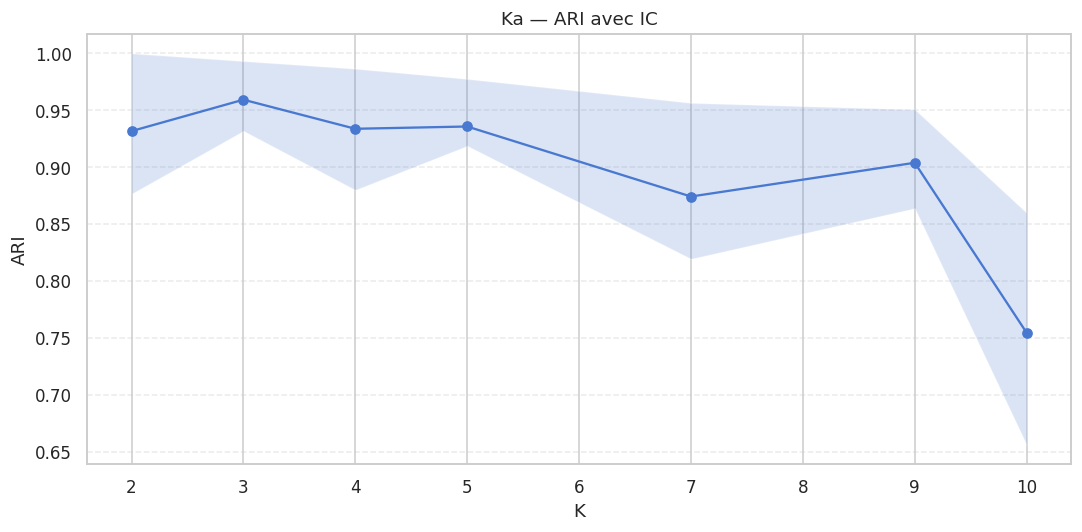

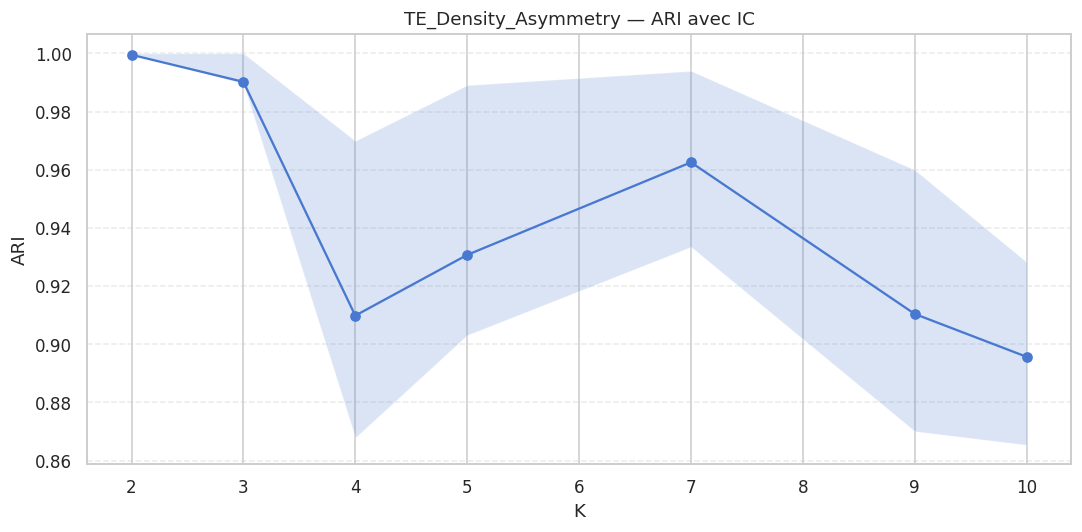

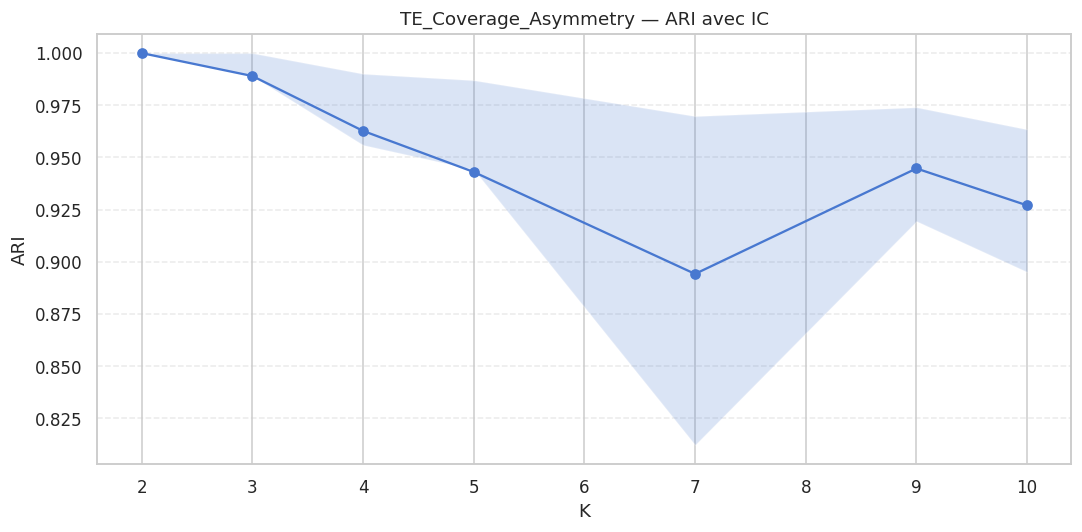

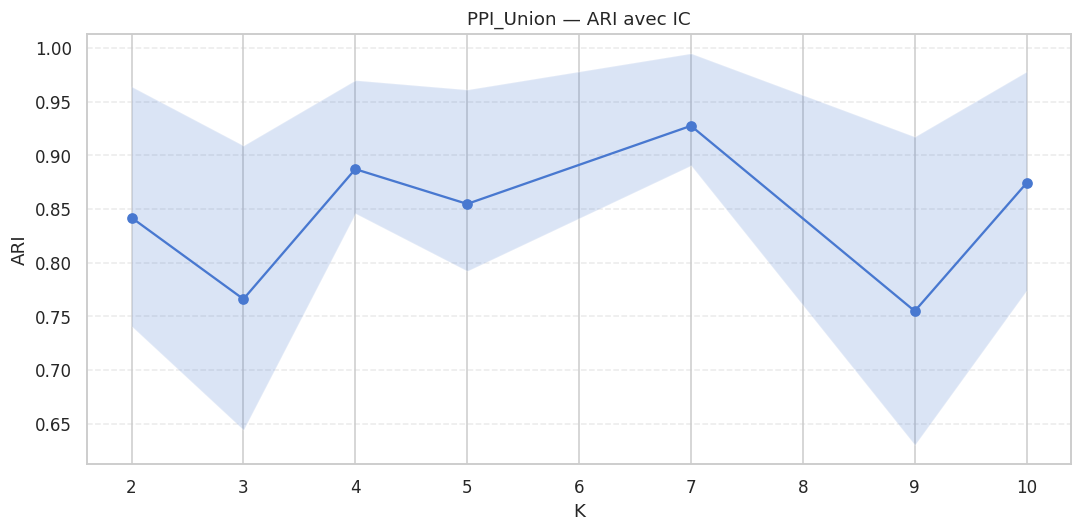

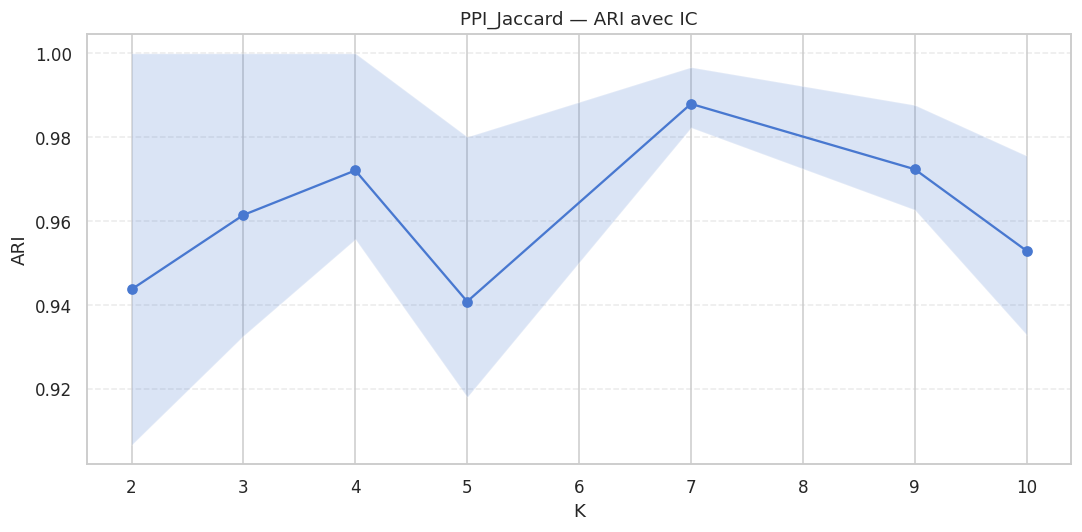

In [25]:
# Visualisation des scores de stabilité 

for family_name in X_top_5_scaled.columns:
    ari_means = [stability_results[family_name][K]["ari_mean"] for K in k_values]
    ari_q25   = [stability_results[family_name][K]["ari_q25"] for K in k_values]
    ari_q75   = [stability_results[family_name][K]["ari_q75"] for K in k_values]

    stability_by_ari_df = pd.DataFrame({
        "K": k_values,
        "mean": ari_means,
        "q25": ari_q25,
        "q75": ari_q75
    })

    figsize=(10,5)
    plt.figure(figsize=figsize)
    plt.plot(stability_by_ari_df["K"], stability_by_ari_df["mean"], marker="o")
    plt.fill_between(stability_by_ari_df["K"], stability_by_ari_df["q25"], stability_by_ari_df["q75"], alpha=0.2)
    plt.xlabel("K")
    plt.ylabel("ARI")
    plt.title(f"{family_name} — ARI avec IC")
    plt.grid(axis="y", linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.savefig(f"Plots/kmeans/lda/stabilité_{family_name}.png", dpi = 300)
    plt.show()

### Critère BIC

In [26]:
# Calculer BIC pour chaque famille et chaque K
from sklearn.mixture import GaussianMixture

# Calculer BIC pour chaque famille et chaque K
bic_results = {}

for descriptor_name in X_top_5_scaled.columns:
    X_family = X_top_5_scaled[[descriptor_name]]
    bic_results[descriptor_name] = []

    for k in k_values:
        gmm = GaussianMixture(n_components=k, random_state=random_state)
        gmm.fit(X_family)
        bic = gmm.bic(X_family)
        bic_results[descriptor_name].append(bic)

### Comparaison synthétique des critères

In [27]:
# def interpret_k_row(row, best_silhouette, best_ari_mean):
#     if row["Partition non triviale ?"] != "Oui":
#         return "Partition triviale / cluster dominant"
#     if row["Silhouette"] >= best_silhouette * 0.95 and row["ARI moyen"] >= best_ari_mean * 0.90:
#         return "Très bon compromis : silhouette et stabilité élevés"
#     if row["Silhouette"] >= best_silhouette * 0.90:
#         if row["ARI moyen"] >= best_ari_mean * 0.80:
#             return "Bon compromis, stabilité correcte"
#         return "Bonne cohésion, stabilité moyenne"
#     if row["ARI moyen"] >= best_ari_mean * 0.90:
#         return "Stabilité forte mais silhouette un peu plus faible"
#     return "Moins recommandé : ni cohésion ni stabilité optimales"

def build_final_selection_table(family_name):
    rows = []
    df_partition = summary_tables[family_name].set_index("K")

    for i, K in enumerate(k_values):
        inertia = kmeans_res[family_name]["inertia"][i]
        silhouette = kmeans_res[family_name]["silhouette"][i]
        ari_mean = stability_results[family_name][K]["ari_mean"]
        ari_median = stability_results[family_name][K]["ari_median"]
        taille_min = df_partition.loc[K, "Taille min"]
        taille_max = df_partition.loc[K, "Taille max"]
        partition_ok = df_partition.loc[K, "Acceptabilité partition"]
        partition_ok = "Oui" if partition_ok == "Oui" else "Non"
        bic = bic_results[family_name][i]

        rows.append({
            "K": K,
            "Inertie": inertia,
            "Silhouette": silhouette,
            "ARI moyen": ari_mean,
            "ARI médian": ari_median,
            "Taille min": taille_min,
            "Taille max": taille_max,
            "Partition non triviale ?": partition_ok,
            "BIC": bic
        })

    table = pd.DataFrame(rows)
    best_silhouette = table["Silhouette"].max()
    best_ari_mean = table["ARI moyen"].max()
    # Ajouter inertie pour K=1
    inertia = inertia_k1(X_top_5_scaled[[family_name]])
    table.loc[-1] = {
        "K": 1,
        "Inertie": inertia,
        "Silhouette": np.nan,
        "ARI moyen": np.nan,
        "ARI médian": np.nan,
        "Taille min": np.nan,
        "Taille max": np.nan,
        "Partition non triviale ?": np.nan,
        "BIC": np.nan
    }
    table.index = table.index + 1  # décaler l'index pour K=1
    table = table.sort_index()  # trier par index pour que K=1

    return table

ka_to_summarize = "Ka"
final_table_ka = build_final_selection_table(ka_to_summarize)

print("Table Ka : \n")
final_table_ka


Inertie pour K=1 Ka : 444.0156717835881
Table Ka : 



,K,Inertie,Silhouette,ARI moyen,ARI médian,Taille min,Taille max,Partition non triviale ?,BIC
0,1,[444.0156717835881],NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,116.265396,0.650850,0.931661,0.985427,138.0,306.0,Oui,1102.702137
2,3,44.814539,0.640531,0.959269,0.964342,81.0,230.0,Oui,1070.369148
3,4,27.302563,0.601431,0.933714,0.953527,73.0,174.0,Oui,1077.697678
4,5,18.324654,0.584779,0.935722,0.952379,41.0,174.0,Oui,1095.875205
5,7,9.611898,0.557657,0.874195,0.872984,33.0,119.0,Oui,1129.121874
6,9,5.816776,0.555332,0.903849,0.913928,11.0,96.0,Oui,1156.973327
7,10,4.889703,0.557220,0.754487,0.733699,4.0,104.0,Oui,1173.090399


In [28]:
# Faire boucle de tableau récapitulatif sur les descripteurs de X_top_5_scaled.columns
for col in X_top_5_scaled.columns:
    print(f"\nTableau récapitulatif pour {col} :\n")
    final_table = build_final_selection_table(col)
    print(final_table.to_string(index=False))


Tableau récapitulatif pour Ka :


Inertie pour K=1 Ka : 444.0156717835881
 K             Inertie  Silhouette  ARI moyen  ARI médian  Taille min  Taille max Partition non triviale ?         BIC
 1 [444.0156717835881]         NaN        NaN         NaN         NaN         NaN                      NaN         NaN
 2          116.265396    0.650850   0.931661    0.985427       138.0       306.0                      Oui 1102.702137
 3           44.814539    0.640531   0.959269    0.964342        81.0       230.0                      Oui 1070.369148
 4           27.302563    0.601431   0.933714    0.953527        73.0       174.0                      Oui 1077.697678
 5           18.324654    0.584779   0.935722    0.952379        41.0       174.0                      Oui 1095.875205
 7            9.611898    0.557657   0.874195    0.872984        33.0       119.0                      Oui 1129.121874
 9            5.816776    0.555332   0.903849    0.913928        11.0        96.0           

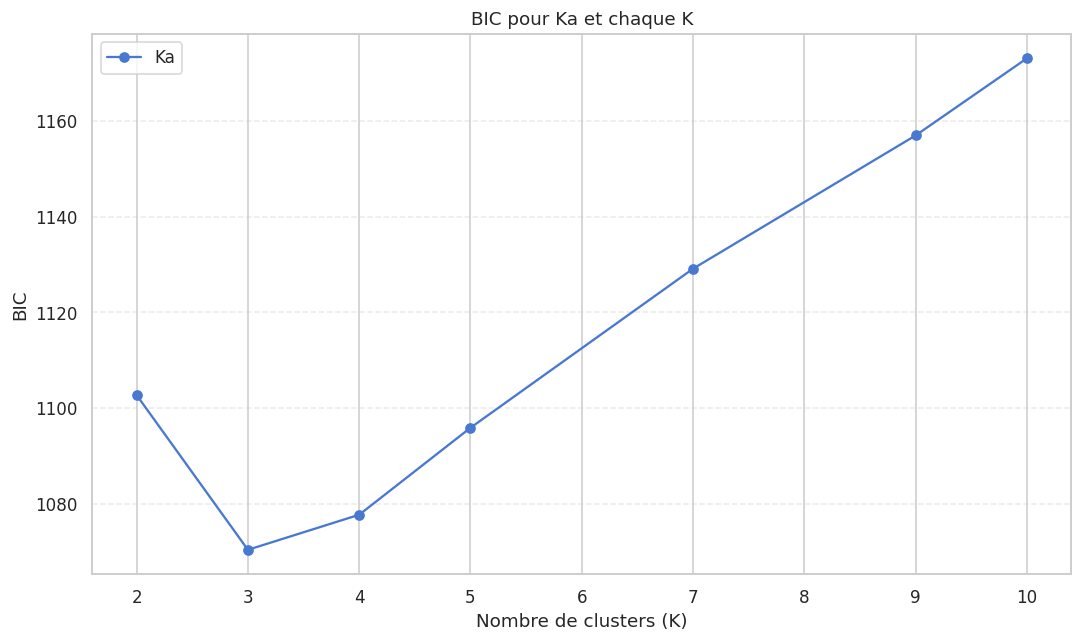

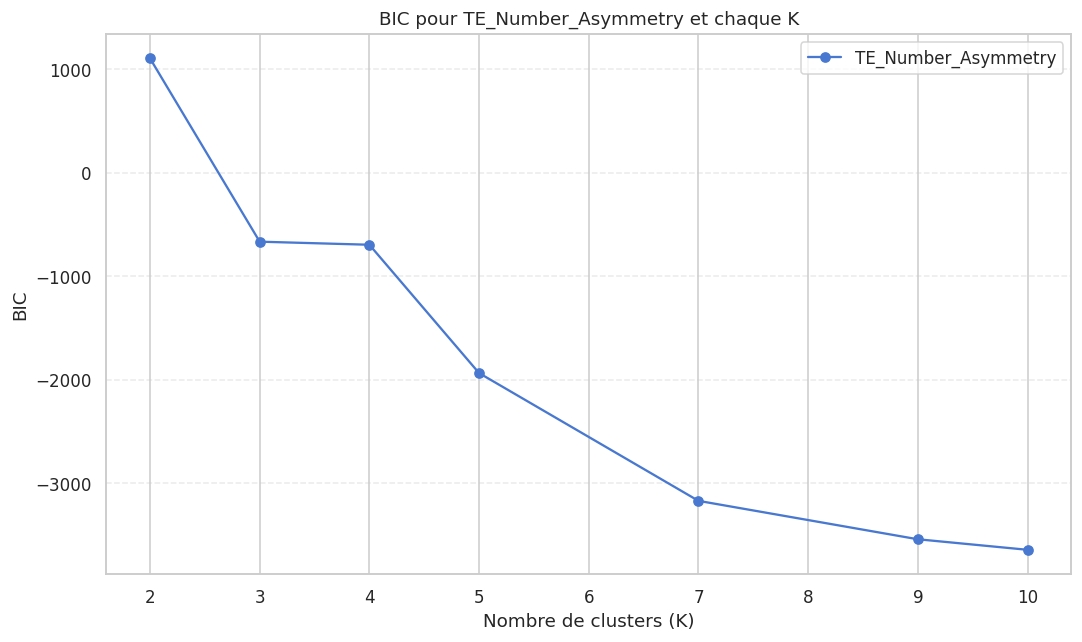

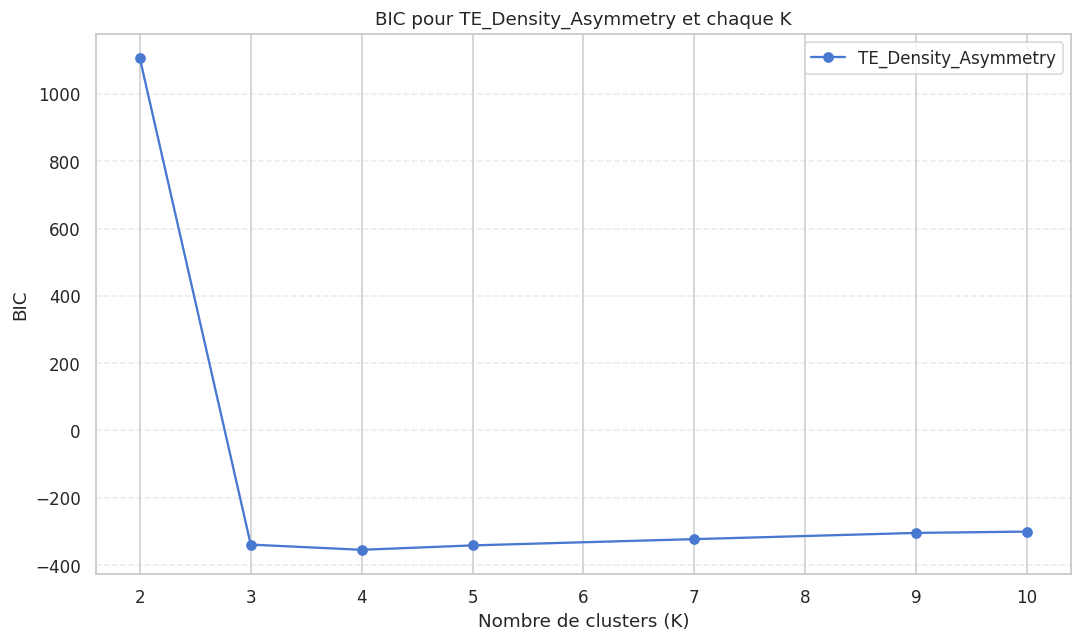

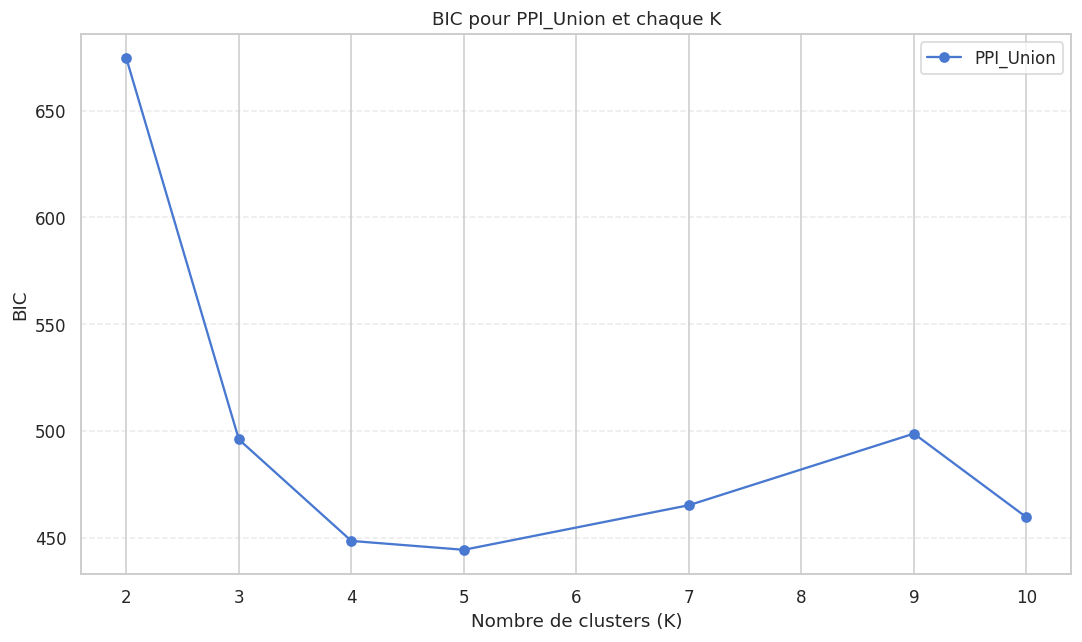

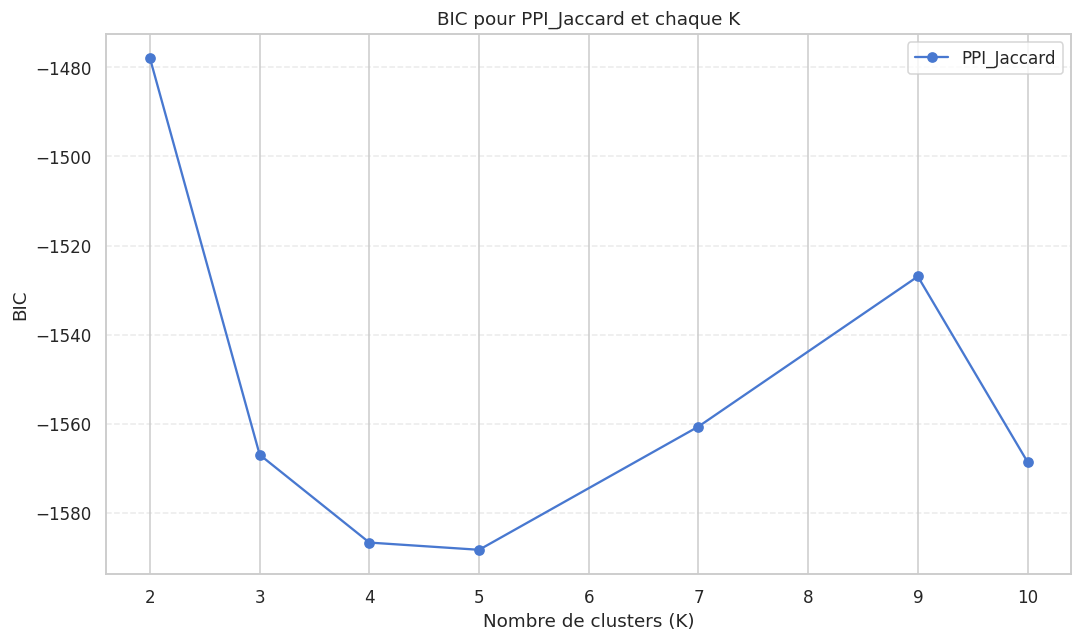

In [24]:
# Représenter graphiquement le BIC pour chaque descripteur et chaque K

for descriptor_name in X_top_5_scaled.columns:
    plt.figure(figsize=(10, 6))
    plt.plot(k_values, bic_results[descriptor_name], marker='o', label=descriptor_name)
    plt.title(f'BIC pour {descriptor_name} et chaque K')
    plt.xlabel('Nombre de clusters (K)')
    plt.ylabel('BIC')
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.4)
    plt.tight_layout()
    # plt.savefig('Plots/kmeans/lda/bic_all_descriptors.png', dpi=300, bbox_inches='tight')
    plt.show()

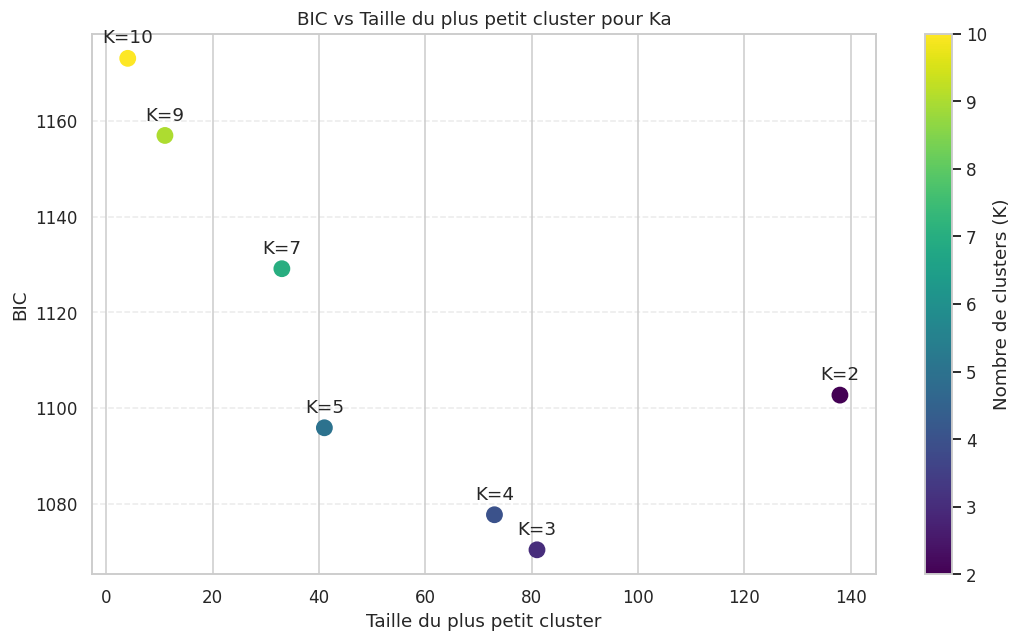

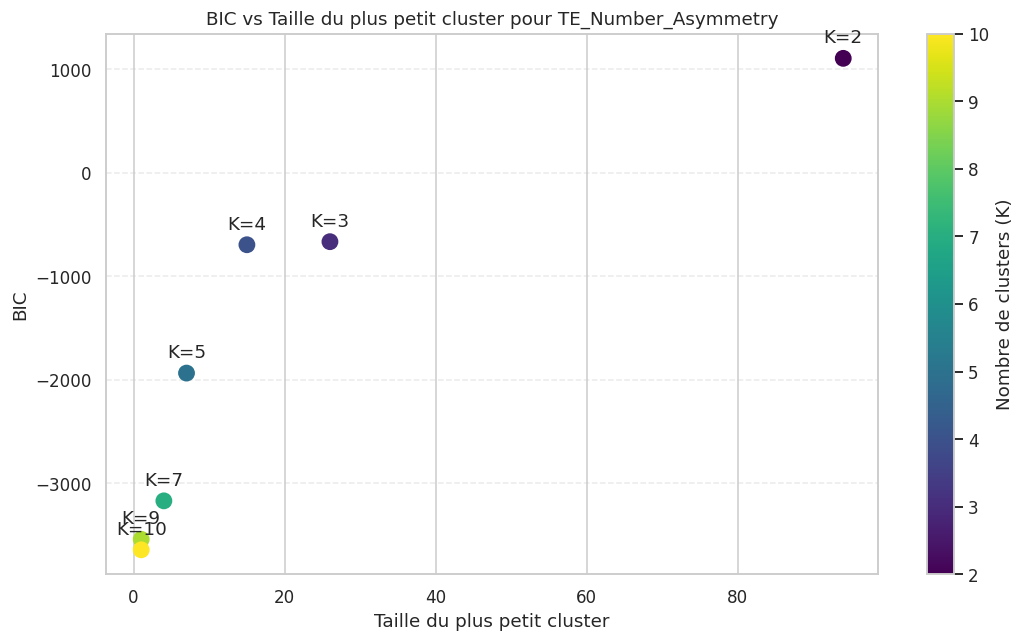

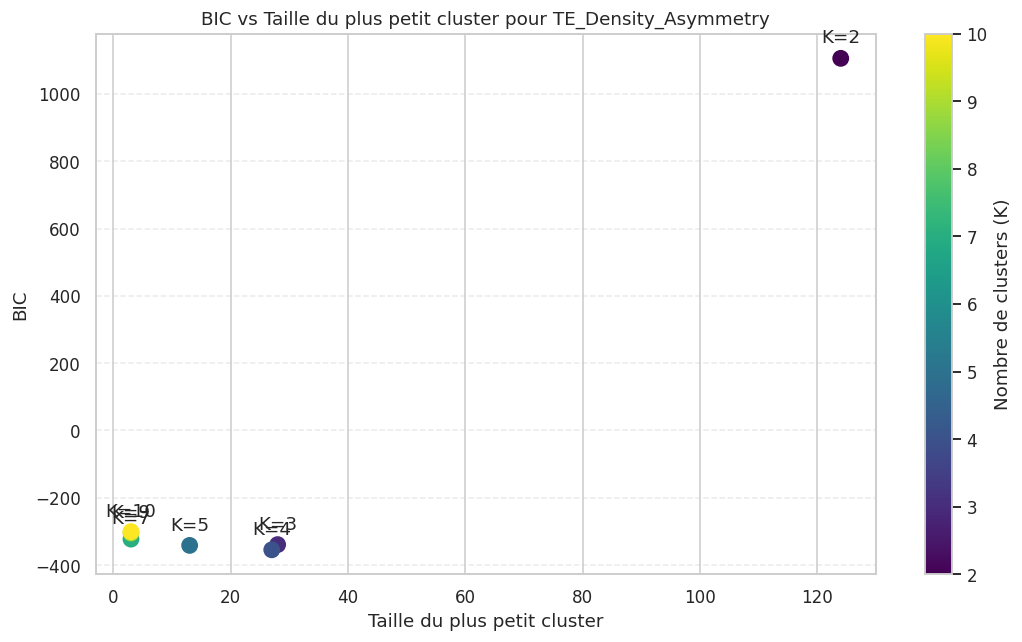

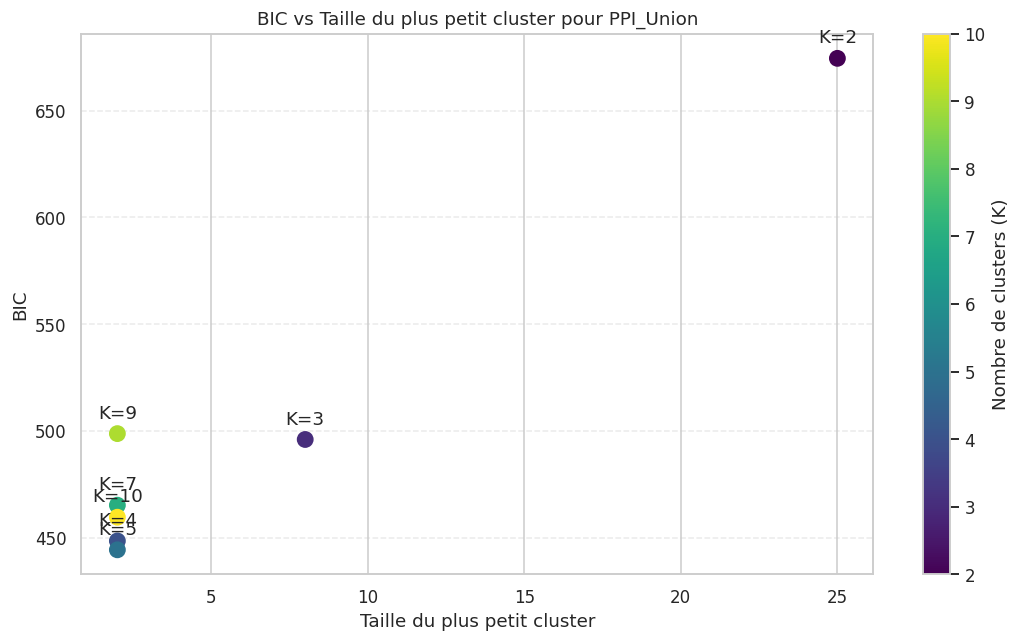

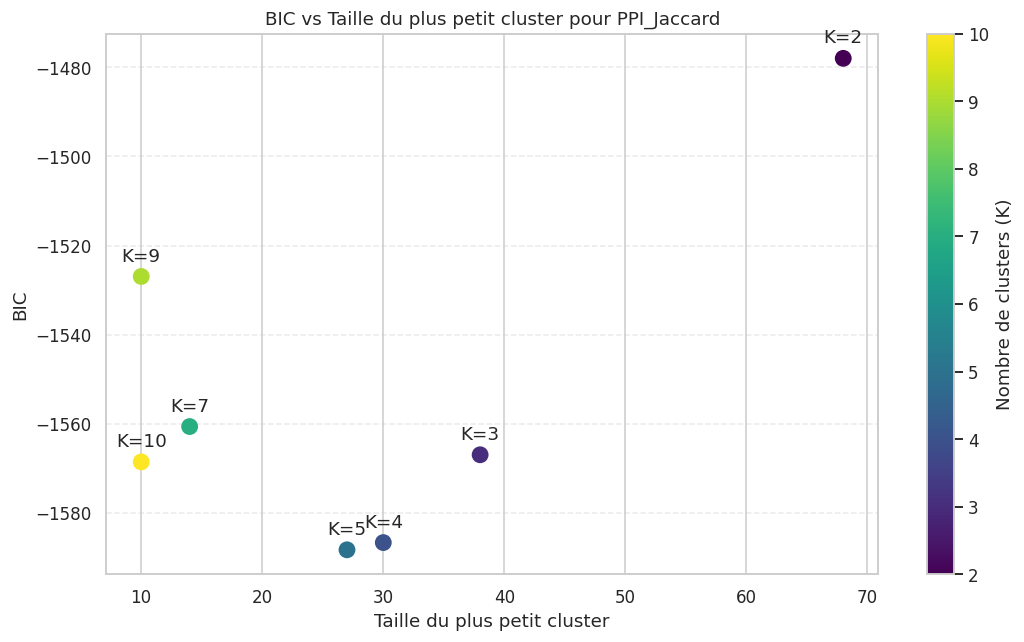

In [25]:
# Visualisation du BIC vs la taille du plus petit cluster pour chaque valeur de K
for descriptor_name in X_top_5_scaled.columns:
    df_partition = summary_tables[descriptor_name].set_index("K")
    bic_values = bic_results[descriptor_name]
    taille_min_values = df_partition["Taille min"].values

    plt.figure(figsize=(10, 6))
    plt.scatter(taille_min_values, bic_values, c=k_values, cmap='viridis', s=100)
    for i, k in enumerate(k_values):
        plt.annotate(f'K={k}', (taille_min_values[i], bic_values[i]), textcoords="offset points", xytext=(0,10), ha='center')
    plt.title(f'BIC vs Taille du plus petit cluster pour {descriptor_name}')
    plt.xlabel('Taille du plus petit cluster')
    plt.ylabel('BIC')
    plt.colorbar(label='Nombre de clusters (K)')
    plt.grid(axis='y', linestyle='--', alpha=0.4)
    plt.tight_layout()
    # plt.savefig(f'Plots/kmeans/lda/bic_vs_taille_min_{descriptor_name}.png', dpi=300, bbox_inches='tight')
    plt.show()

### Comparaison ARI couple descripteurs

In [26]:
# Regarder les couples de descripteurs sur la correspondance du clustering et calculer l'ARI pour chaque couple des 5 descripteurs les plus importants selon LDA pour les k sélectionnés.
# On va faire un tableau avec les ARI pour chaque couple de descripteurs et chaque k.
ari_matrix = pd.DataFrame(index=X_top_5_scaled.columns, columns=X_top_5_scaled.columns)

k_ka = 3
k_te_number_asymmetry = 3
k_te_density_asymmetry = 4
k_ppi_union = 5
k_ppi_jaccard = 4 # potentiellement 5

# Regarder les couples de descripteurs et calculer l'ARI pour chaque couple
for i, desc1 in enumerate(X_top_5_scaled.columns):
    for j, desc2 in enumerate(X_top_5_scaled.columns):
        if i <= j:  # éviter les doublons et la diagonale
            labels1 = kmeans_res[desc1]['labels'][k_values.index(eval(f'k_{desc1.lower()}'))]
            labels2 = kmeans_res[desc2]['labels'][k_values.index(eval(f'k_{desc2.lower()}'))]
            ari = adjusted_rand_score(labels1, labels2)
            ari_matrix.loc[desc1, desc2] = ari
            ari_matrix.loc[desc2, desc1] = ari  # symétrique

print("\nMatrice ARI entre les descripteurs pour les k sélectionnés :")
print(ari_matrix.to_string())


Matrice ARI entre les descripteurs pour les k sélectionnés :
                            Ka TE_Number_Asymmetry TE_Density_Asymmetry PPI_Union PPI_Jaccard
Ka                         1.0           -0.007192             0.002789  0.002812   -0.047162
TE_Number_Asymmetry  -0.007192                 1.0             0.422446 -0.022615   -0.020937
TE_Density_Asymmetry  0.002789            0.422446                  1.0 -0.008437   -0.012403
PPI_Union             0.002812           -0.022615            -0.008437       1.0    0.156436
PPI_Jaccard          -0.047162           -0.020937            -0.012403  0.156436         1.0


### Matrices Z selon les clusters par descripteur sans composantes t-SNE

In [27]:
# Récupérer la matrice d'adjacence pour les clusters K-means par famille de descripteurs
family_adjacency_matrices = {}

for family_name in X_top_5_scaled.columns:

    if (family_name== 'Ka' or family_name== 'TE_Number_Asymmetry'):
        optimal_k = 3
    elif (family_name == 'TE_Density_Asymmetry' or family_name == 'PPI_Jaccard'):
        optimal_k = 4
    else:
        optimal_k = 5

    X_family = X_top_5_scaled[[family_name]]
    kmeans_family = KMeans(n_clusters=optimal_k, n_init=n_init, random_state=random_state, init='k-means++')
    labels_family = kmeans_family.fit_predict(X_family)
    
    Z_family = pd.DataFrame(X_family, columns=X_family.columns)
    Z_family['Cluster'] = labels_family
    
    Z_family_binary = pd.get_dummies(Z_family['Cluster'], prefix='Cluster').astype(int)
    
    adjacency_matrix_family = Z_family_binary.values @ Z_family_binary.values.T
    adjacency_matrix_family = adjacency_matrix_family - np.diag(np.diag(adjacency_matrix_family))  # Soustraire les éléments diagonaux
    family_adjacency_matrices[family_name] = adjacency_matrix_family
    
    print(f"\nMatrice d'adjacence pour la famille '{family_name}':")
    print(f"Shape: {adjacency_matrix_family.shape}")
    print(f"Nombre de paires dans le même cluster: {(adjacency_matrix_family.sum()/2):.0f}")
    # Diviser par 2 pour ne pas compter les paires (i,j) et (j,i)


Matrice d'adjacence pour la famille 'Ka':
Shape: (444, 444)
Nombre de paires dans le même cluster: 38353

Matrice d'adjacence pour la famille 'TE_Number_Asymmetry':
Shape: (444, 444)
Nombre de paires dans le même cluster: 48421

Matrice d'adjacence pour la famille 'TE_Density_Asymmetry':
Shape: (444, 444)
Nombre de paires dans le même cluster: 30256

Matrice d'adjacence pour la famille 'PPI_Union':
Shape: (444, 444)
Nombre de paires dans le même cluster: 43286

Matrice d'adjacence pour la famille 'PPI_Jaccard':
Shape: (444, 444)
Nombre de paires dans le même cluster: 45553


In [28]:
# Sauvegarder les matrices d'adjacence dans un fichier CSV
for family_name, adjacency_matrix in family_adjacency_matrices.items():
    adjacency_df = pd.DataFrame(adjacency_matrix, index=X_top_5_scaled.index, columns=X_top_5_scaled.index)
    adjacency_df.to_csv(f'Données/adjacency/lda/adjacency_matrix_{family_name}.csv')
    print(f"Matrice d'adjacence pour la famille '{family_name}' sauvegardée dans 'Données/adjacency/lda/adjacency_matrix_{family_name}.csv'")

Matrice d'adjacence pour la famille 'Ka' sauvegardée dans 'Données/adjacency/lda/adjacency_matrix_Ka.csv'
Matrice d'adjacence pour la famille 'TE_Number_Asymmetry' sauvegardée dans 'Données/adjacency/lda/adjacency_matrix_TE_Number_Asymmetry.csv'
Matrice d'adjacence pour la famille 'TE_Density_Asymmetry' sauvegardée dans 'Données/adjacency/lda/adjacency_matrix_TE_Density_Asymmetry.csv'
Matrice d'adjacence pour la famille 'PPI_Union' sauvegardée dans 'Données/adjacency/lda/adjacency_matrix_PPI_Union.csv'
Matrice d'adjacence pour la famille 'PPI_Jaccard' sauvegardée dans 'Données/adjacency/lda/adjacency_matrix_PPI_Jaccard.csv'


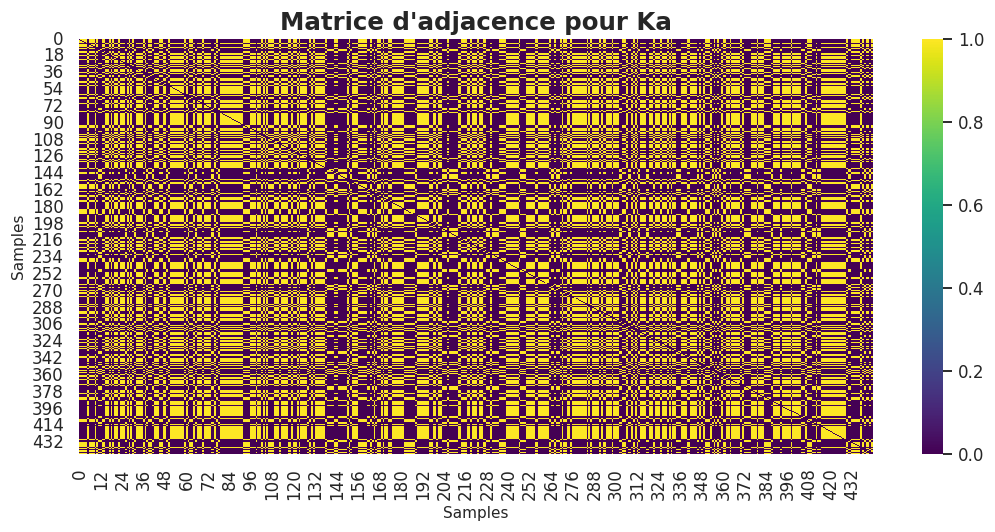

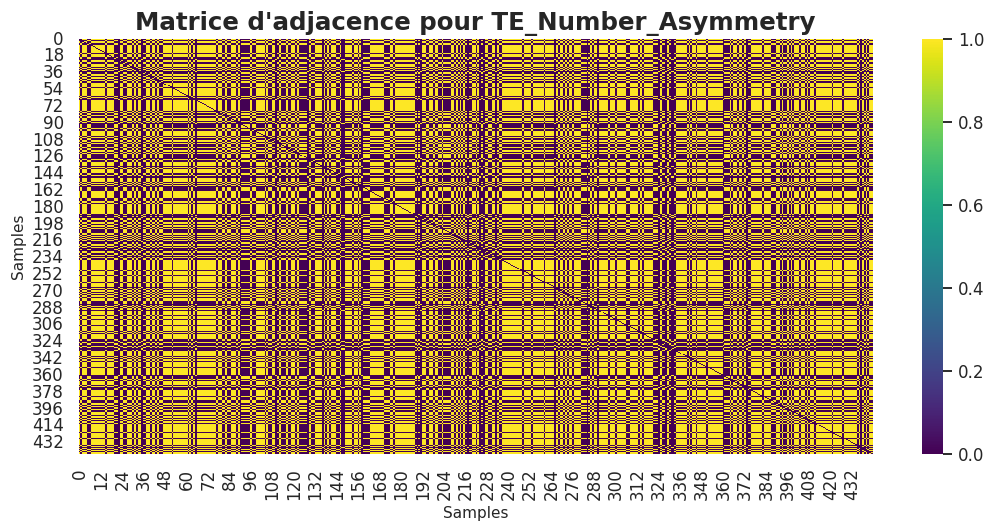

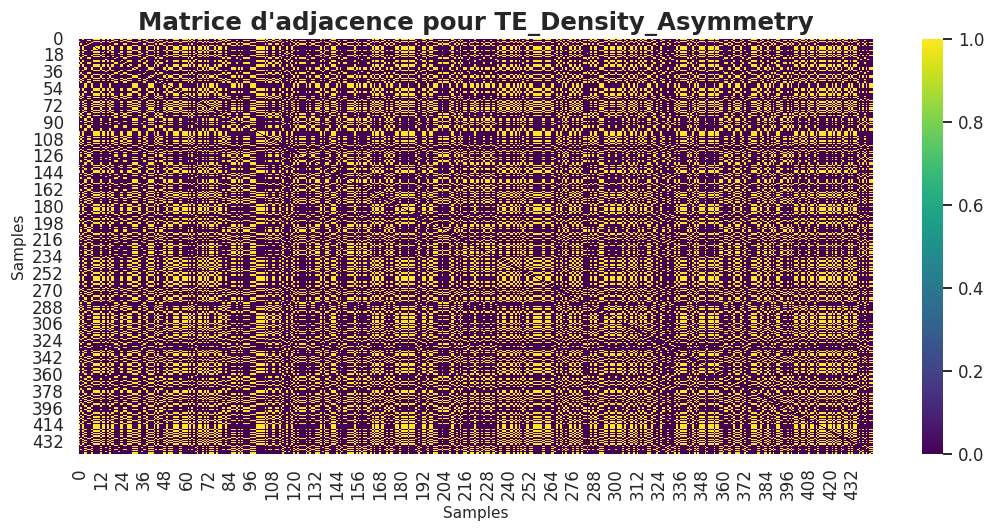

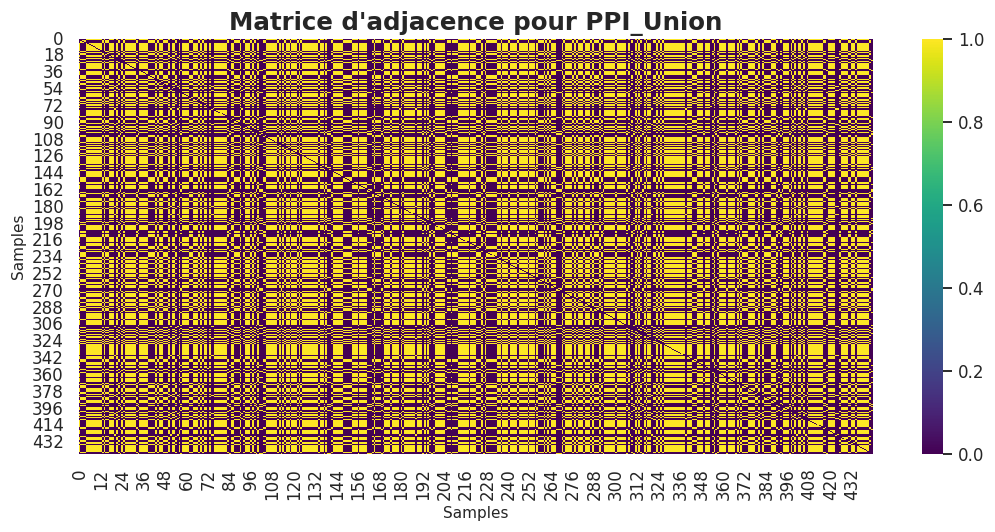

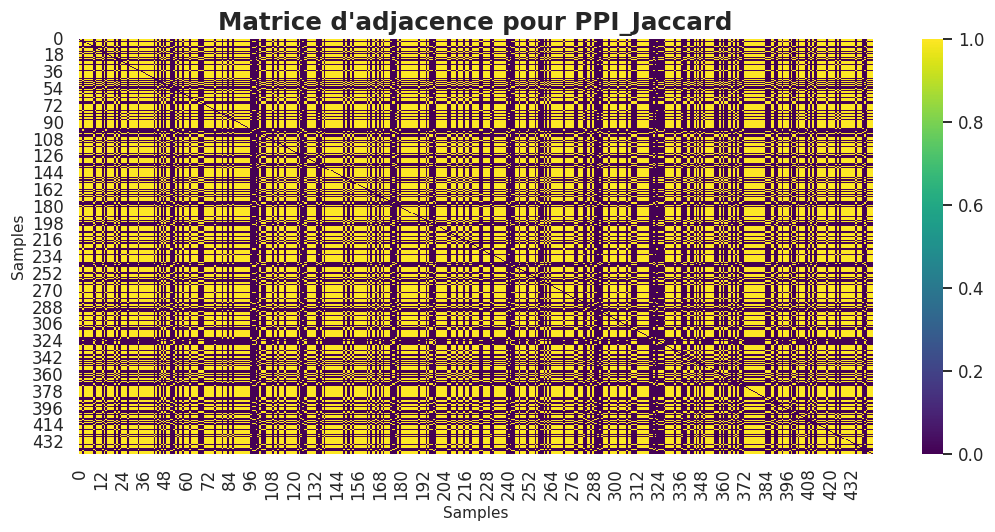

In [29]:
# Heatmap de la matrice d'adjacence par descripteurs
for idx, (family_name, adjacency_matrix) in enumerate(family_adjacency_matrices.items()):
    figsize = (10, 5)
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_title(f'Matrice d\'adjacence pour {family_name}', fontsize=16, fontweight='bold')
    sns.heatmap(adjacency_matrix, ax=ax, cmap='viridis', cbar=True)
    ax.set_xlabel('Samples', fontsize=10)
    ax.set_ylabel('Samples', fontsize=10)
    plt.tight_layout()
    plt.show()

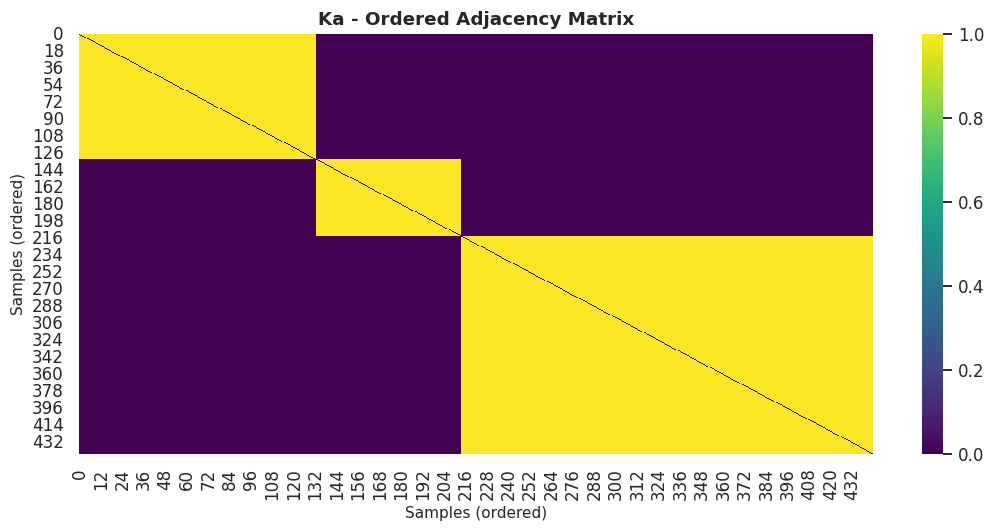

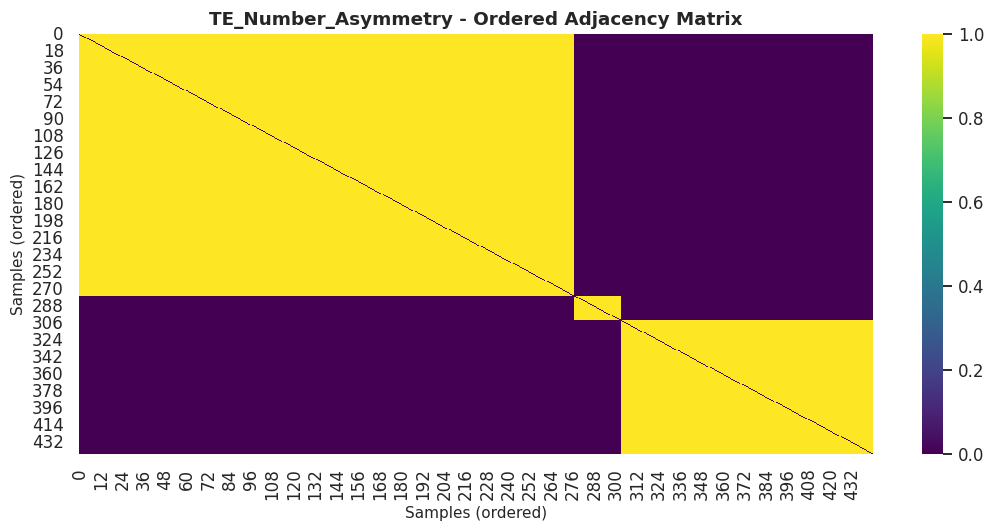

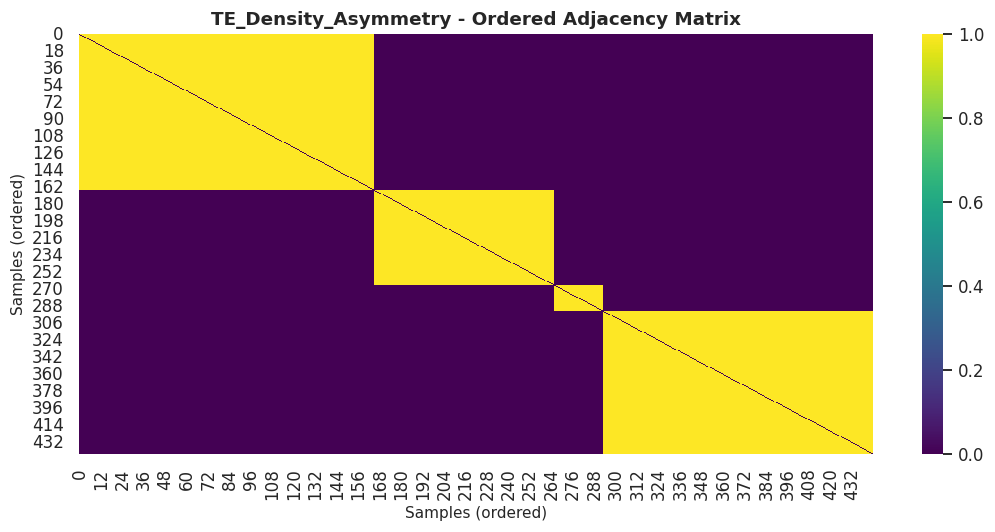

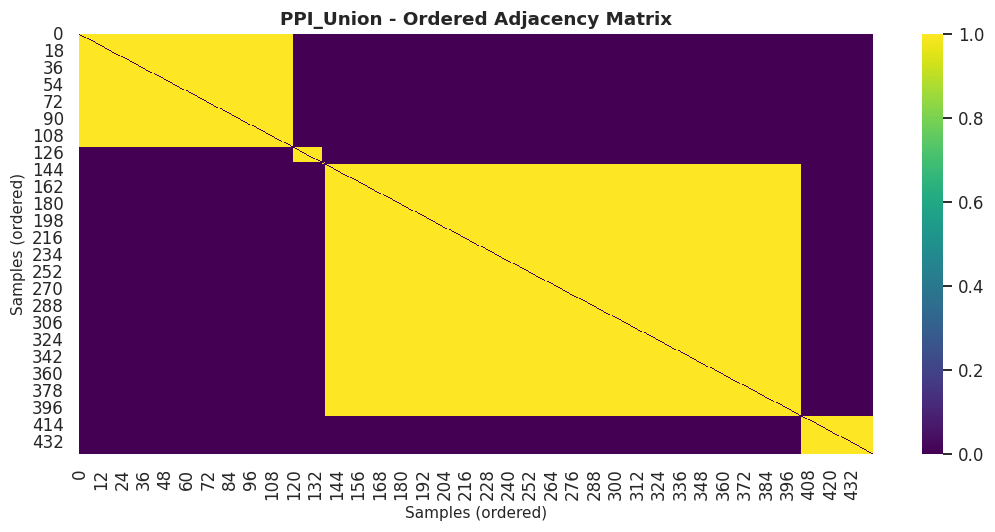

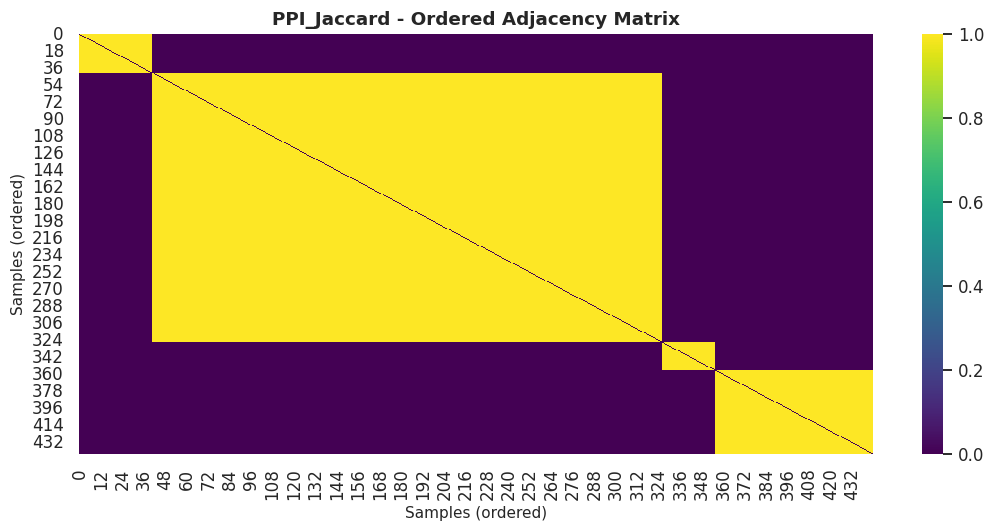

In [30]:
# Ordonnancement matrice d'adjacence pour regrouper les points appartenant au même cluster
for idx, (family_name, adjacency_matrix) in enumerate(family_adjacency_matrices.items()):

    figsize = (10, 5)
    fig, ax = plt.subplots(figsize=figsize)
    # Recalculer les clusters pour cette famille spécifique
    if (family_name== 'Ka' or family_name== 'TE_Number_Asymmetry'):
            optimal_k = 3
    elif (family_name == 'TE_Density_Asymmetry' or family_name == 'PPI_Jaccard'):
        optimal_k = 4
    else:
        optimal_k = 5

    X_family = X_top_5_scaled[[family_name]]
    kmeans_family = KMeans(n_clusters=optimal_k, n_init=n_init, random_state=random_state, init='k-means++')
    labels_family = kmeans_family.fit_predict(X_family)
    
    # Ordonner la matrice d'adjacence en regroupant les points du même cluster
    ordered_indices = np.argsort(labels_family)
    ordered_adjacency = adjacency_matrix[ordered_indices][:, ordered_indices]
    
    sns.heatmap(ordered_adjacency, ax=ax, cmap='viridis', cbar=True)
    plt.title(f'{family_name} - Ordered Adjacency Matrix', fontsize=12, fontweight='bold')
    plt.xlabel('Samples (ordered)', fontsize=10)
    plt.ylabel('Samples (ordered)', fontsize=10)
    plt.tight_layout()
# plt.savefig('Plots/kmeans/lda/ordered_adjacency_matrices.png', dpi=300)
    plt.show()

In [31]:
# On va calculer pour chaque descripteurs le nombre de points qui sont dans le même cluster
cluster_comparison = pd.DataFrame(index=[X_top_5_scaled.columns], columns=[f'Cluster {i}' for i in range(optimal_k)])


for family_name in X_top_5_scaled.columns:
    # Recalculer les clusters pour cette famille spécifique
    if (family_name== 'Ka' or family_name== 'TE_Number_Asymmetry'):
        optimal_k = 3
    elif (family_name == 'TE_Density_Asymmetry' or family_name == 'PPI_Jaccard'):
        optimal_k = 4
    else:
        optimal_k = 5
    
    X_family = X_top_5_scaled[[family_name]]
    kmeans_family = KMeans(n_clusters=optimal_k, n_init=n_init, random_state=random_state, init='k-means++')
    labels_family = kmeans_family.fit_predict(X_family)
    
    # Compter le nombre de points dans chaque cluster pour ce descripteur
    for cluster_id in range(optimal_k):
        num_points_in_cluster = np.sum(labels_family == cluster_id)
        cluster_comparison.loc[family_name, f'Cluster {cluster_id}'] = num_points_in_cluster

    print("\nComparaison entre le descripteur et les clusters:")
    print(cluster_comparison)


Comparaison entre le descripteur et les clusters:
                     Cluster 0 Cluster 1 Cluster 2 Cluster 3
Ka                         133        81       230       NaN
TE_Number_Asymmetry        NaN       NaN       NaN       NaN
TE_Density_Asymmetry       NaN       NaN       NaN       NaN
PPI_Union                  NaN       NaN       NaN       NaN
PPI_Jaccard                NaN       NaN       NaN       NaN

Comparaison entre le descripteur et les clusters:
                     Cluster 0 Cluster 1 Cluster 2 Cluster 3
Ka                         133        81       230       NaN
TE_Number_Asymmetry        277        26       141       NaN
TE_Density_Asymmetry       NaN       NaN       NaN       NaN
PPI_Union                  NaN       NaN       NaN       NaN
PPI_Jaccard                NaN       NaN       NaN       NaN

Comparaison entre le descripteur et les clusters:
                     Cluster 0 Cluster 1 Cluster 2 Cluster 3
Ka                         133        81       230    

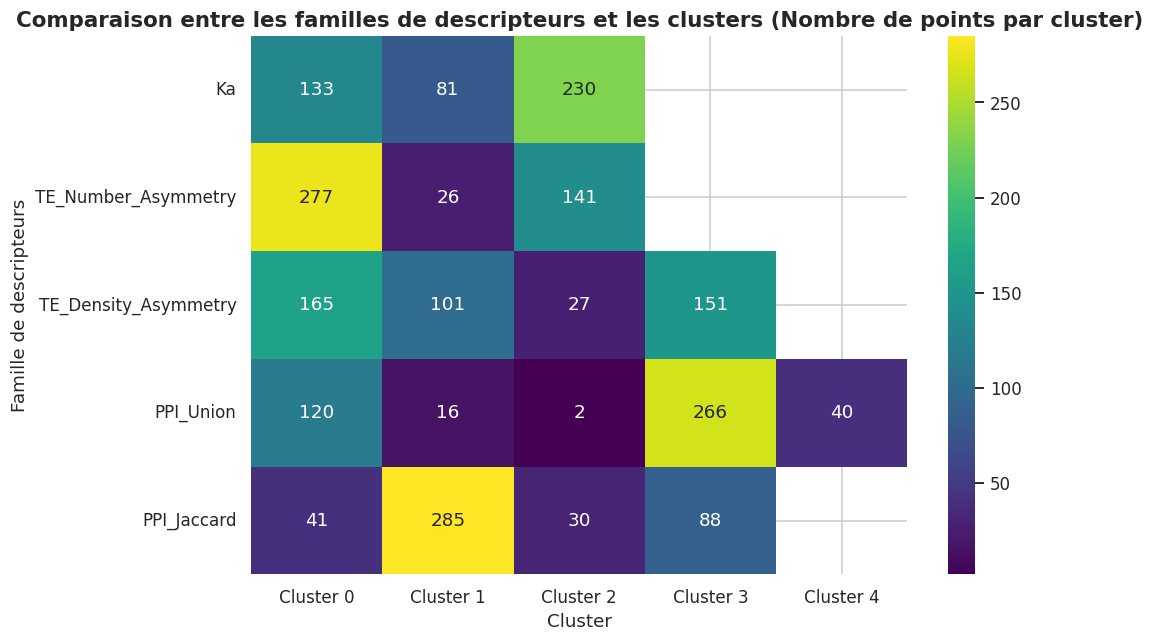

In [32]:
# Faire heatmap de cluster_comparison
plt.figure(figsize=(10, 6))
sns.heatmap(cluster_comparison.astype(float), annot=True, fmt=".0f", cmap='viridis', cbar=True)
plt.title('Comparaison entre les familles de descripteurs et les clusters (Nombre de points par cluster)', fontsize=14, fontweight='bold')
plt.xlabel('Cluster', fontsize=12)
plt.ylabel('Famille de descripteurs', fontsize=12)
plt.tight_layout()
# plt.savefig('Plots/kmeans/family/cluster_comparison_heatmap.png', dpi=300)
plt.show()

In [33]:
# --- Calcul des tailles ET ratios redondant/divergent par cluster ---
max_k = max(7, 5, 2, 3)
columns = [f'Cluster {i}' for i in range(max_k)]

cluster_comparison = pd.DataFrame(index=X_top_5_scaled.columns, columns=columns, dtype=float)
ratio_comparison   = pd.DataFrame(index=X_top_5_scaled.columns, columns=columns, dtype=float)

y_train = pd.read_csv("Données/Y_train_clean.csv")
classifications = y_train['Classification'].values  # 0=redondant, 1=divergent

for family_name in X_top_5_scaled.columns:
    # Recalculer les clusters pour cette famille spécifique
    if (family_name== 'Ka' or family_name== 'TE_Number_Asymmetry'):
            optimal_k = 3
    elif (family_name == 'TE_Density_Asymmetry' or family_name == 'PPI_Jaccard'):
        optimal_k = 4
    else:
        optimal_k = 5

    X_family = X_top_5_scaled[[family_name]]
    kmeans_family = KMeans(n_clusters=optimal_k, n_init=n_init,
                           random_state=random_state, init='k-means++')
    labels_family = kmeans_family.fit_predict(X_family)

    # Calculer taille et ratio pour chaque cluster
    cluster_sizes  = []
    cluster_ratios = []
    for cluster_id in range(optimal_k):
        mask_cluster = labels_family == cluster_id
        n = int(np.sum(mask_cluster))
        n_div = int(np.sum(classifications[mask_cluster] == 1))
        n_red = n - n_div
        ratio = n_red / n_div if n_div > 0 else np.inf  # redondant/divergent
        cluster_sizes.append(n)
        cluster_ratios.append(ratio)

    # Trier les deux listes ensemble par taille décroissante
    sorted_pairs = sorted(zip(cluster_sizes, cluster_ratios), key=lambda x: x[0], reverse=True)

    for rank, (size, ratio) in enumerate(sorted_pairs):
        cluster_comparison.loc[family_name, f'Cluster {rank}'] = size
        ratio_comparison.loc[family_name,   f'Cluster {rank}'] = ratio

# --- Construction des annotations combinées ---
# Chaque cellule affiche : "N pts\nR:D = x.xx"
annot_matrix = pd.DataFrame(index=cluster_comparison.index, columns=cluster_comparison.columns, dtype=object)
nan_mask = cluster_comparison.isna()

for fam in cluster_comparison.index:
    for col in cluster_comparison.columns:
        if nan_mask.loc[fam, col]:
            annot_matrix.loc[fam, col] = ""
        else:
            n     = int(cluster_comparison.loc[fam, col])
            ratio = ratio_comparison.loc[fam, col]
            ratio_str = f"{ratio:.2f}" if not np.isinf(ratio) else "∞"
            annot_matrix.loc[fam, col] = f"{n} paires\nR/D={ratio_str}"

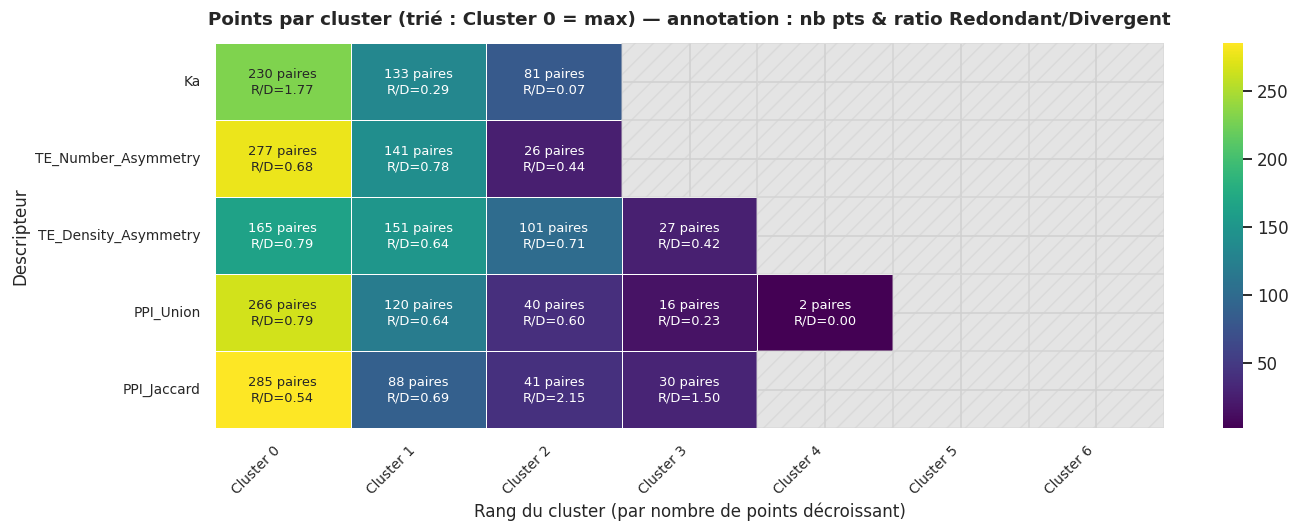

In [34]:
# --- Heatmap ---
fig, ax = plt.subplots(figsize=(13, 5))

sns.heatmap(
    cluster_comparison.astype(float).values,
    annot=annot_matrix.values,
    fmt="",                  # fmt vide car les annotations sont des strings
    cmap='viridis',
    cbar=True,
    mask=nan_mask.values,
    linewidths=0.5,
    linecolor='white',
    ax=ax,
    annot_kws={"size": 8.5}
)

for i in range(cluster_comparison.shape[0]):
    for j in range(cluster_comparison.shape[1]):
        if nan_mask.iloc[i, j]:
            ax.add_patch(plt.Rectangle(
                (j, i), 1, 1,
                fill=True, color='lightgrey', hatch='//', alpha=0.6
            ))

ax.set_title(
    'Points par cluster (trié : Cluster 0 = max) — annotation : nb pts & ratio Redondant/Divergent',
    fontsize=12, fontweight='bold', pad=12
)
ax.set_xlabel('Rang du cluster (par nombre de points décroissant)', fontsize=11)
ax.set_ylabel('Descripteur', fontsize=11)
ax.set_yticks(np.arange(cluster_comparison.shape[0]) + 0.5)
ax.set_yticklabels(cluster_comparison.index, rotation=0, fontsize=9)
ax.set_xticks(np.arange(cluster_comparison.shape[1]) + 0.5)
ax.set_xticklabels(cluster_comparison.columns, rotation=45, ha='right', fontsize=9)
plt.tight_layout()
plt.savefig('Plots/kmeans/lda/cluster_comparison_ratio_heatmap_5.png', dpi=300)
plt.show()

In [35]:
# Additionner les matrices d'adjacence de toutes les descripteurs et compter les nombres dans la matrice résultante
total_adjacency_sum = np.zeros_like(list(family_adjacency_matrices.values())[0])
for adjacency_matrix in family_adjacency_matrices.values():
    total_adjacency_sum += adjacency_matrix

num_zeros = (np.sum(total_adjacency_sum == 0)  - 444 )/ 2 # Nombre de paires de points dans le même cluster pour exactement 0 descripteurs
num_ones = np.sum(total_adjacency_sum == 1) / 2 # Nombre de paires de points dans le même cluster pour exactement 1 descripteur
num_twos = np.sum(total_adjacency_sum == 2) / 2 # Nombre de paires de points dans le même cluster pour exactement 2 descripteurs
num_threes = np.sum(total_adjacency_sum == 3) / 2 # Nombre de paires de points dans le même cluster pour exactement 3 descripteurs
num_fours = np.sum(total_adjacency_sum == 4) / 2 # Nombre de paires de points dans le même cluster pour exactement 4 descripteurs
num_fives = np.sum(total_adjacency_sum == 5) / 2 # Nombre de paires de points dans le même cluster pour exactement 5 descripteurs

print(f"Nombre de paires de points dans le même cluster pour exactement 0 descripteurs: {num_zeros:.0f}")
print(f"Nombre de paires de points dans le même cluster pour exactement 1 descripteur: {num_ones:.0f}")
print(f"\nNombre de paires de points dans le même cluster pour exactement 2 descripteurs: {num_twos:.0f}")
print(f"Nombre de paires de points dans le même cluster pour exactement 3 descripteurs: {num_threes:.0f}")
print(f"Nombre de paires de points dans le même cluster pour exactement 4 descripteurs: {num_fours:.0f}")
print(f"Nombre de paires de points dans le même cluster pour exactement 5 descripteurs: {num_fives:.0f}")

Nombre de paires de points dans le même cluster pour exactement 0 descripteurs: 8753
Nombre de paires de points dans le même cluster pour exactement 1 descripteur: 23137

Nombre de paires de points dans le même cluster pour exactement 2 descripteurs: 31124
Nombre de paires de points dans le même cluster pour exactement 3 descripteurs: 22993
Nombre de paires de points dans le même cluster pour exactement 4 descripteurs: 10190
Nombre de paires de points dans le même cluster pour exactement 5 descripteurs: 2149


In [36]:
num_twos + num_threes + num_fours + num_ones + num_zeros + num_fives

np.float64(98346.0)

In [37]:
print("\nDistribution des valeurs dans la matrice :")
total_count = 0
total_pairs = (total_adjacency_sum.size - 444) / 2

for v in range(6):
    if v == 0:
        count = np.sum(total_adjacency_sum == v) - 444
        count = count / 2
    else:
        count = np.sum(total_adjacency_sum == v) / 2

    pct = 100 * count / total_pairs
    print(f"  Valeur {v} : {int(count):,} paires ({pct:.1f}%)")
    total_count += count



Distribution des valeurs dans la matrice :
  Valeur 0 : 8,753 paires (8.9%)
  Valeur 1 : 23,137 paires (23.5%)
  Valeur 2 : 31,124 paires (31.6%)
  Valeur 3 : 22,993 paires (23.4%)
  Valeur 4 : 10,190 paires (10.4%)
  Valeur 5 : 2,149 paires (2.2%)


#### Matrices d'aggrégation entre familles

In [38]:
# Matrices d'adjacence regroupées par famille

family_groups = {
    "Ka": ["Ka"],
    "TE": ["TE_Number_Asymmetry", "TE_Density_Asymmetry"],
    "PPI": ["PPI_Union", "PPI_Jaccard"]
}

group_adjacency_matrices = {}

for group_name, descriptors in family_groups.items():
    available_descriptors = [
        descriptor
        for descriptor in descriptors
        if descriptor in family_adjacency_matrices
    ]

    if not available_descriptors:
        print(f"Aucune matrice disponible pour la famille {group_name}")
        continue

    group_matrix = sum(
        family_adjacency_matrices[descriptor]
        for descriptor in available_descriptors
    )

    group_adjacency_matrices[group_name] = group_matrix

    print(
        f"{group_name} : "
        f"{', '.join(available_descriptors)} "
        f"-> matrice de forme {group_matrix.shape}"
    )

Ka : Ka -> matrice de forme (444, 444)
TE : TE_Number_Asymmetry, TE_Density_Asymmetry -> matrice de forme (444, 444)
PPI : PPI_Union, PPI_Jaccard -> matrice de forme (444, 444)


In [39]:
print("\nMatrice d'adjacence regroupée par famille :")
for group_name, group_matrix in group_adjacency_matrices.items():
    num_pairs = np.sum(group_matrix) / 2  # Diviser par 2 pour ne pas compter les paires (i,j) et (j,i)
    print(f"{group_name} : {num_pairs:.0f} paires dans le même cluster")


Matrice d'adjacence regroupée par famille :
Ka : 38353 paires dans le même cluster
TE : 78677 paires dans le même cluster
PPI : 88839 paires dans le même cluster


5 meilleurs descripteurs selon la LDA :
['Ka', 'TE_Number_Asymmetry', 'TE_Density_Asymmetry', 'PPI_Union', 'PPI_Jaccard']

Famille : Ka
Descripteurs utilisés : ['Ka']
Forme : (444, 444)
Somme des valeurs : 76706

Famille : TE
Descripteurs utilisés : ['TE_Number_Asymmetry', 'TE_Density_Asymmetry']
Forme : (444, 444)
Somme des valeurs : 157354

Famille : PPI
Descripteurs utilisés : ['PPI_Union', 'PPI_Jaccard']
Forme : (444, 444)
Somme des valeurs : 177678


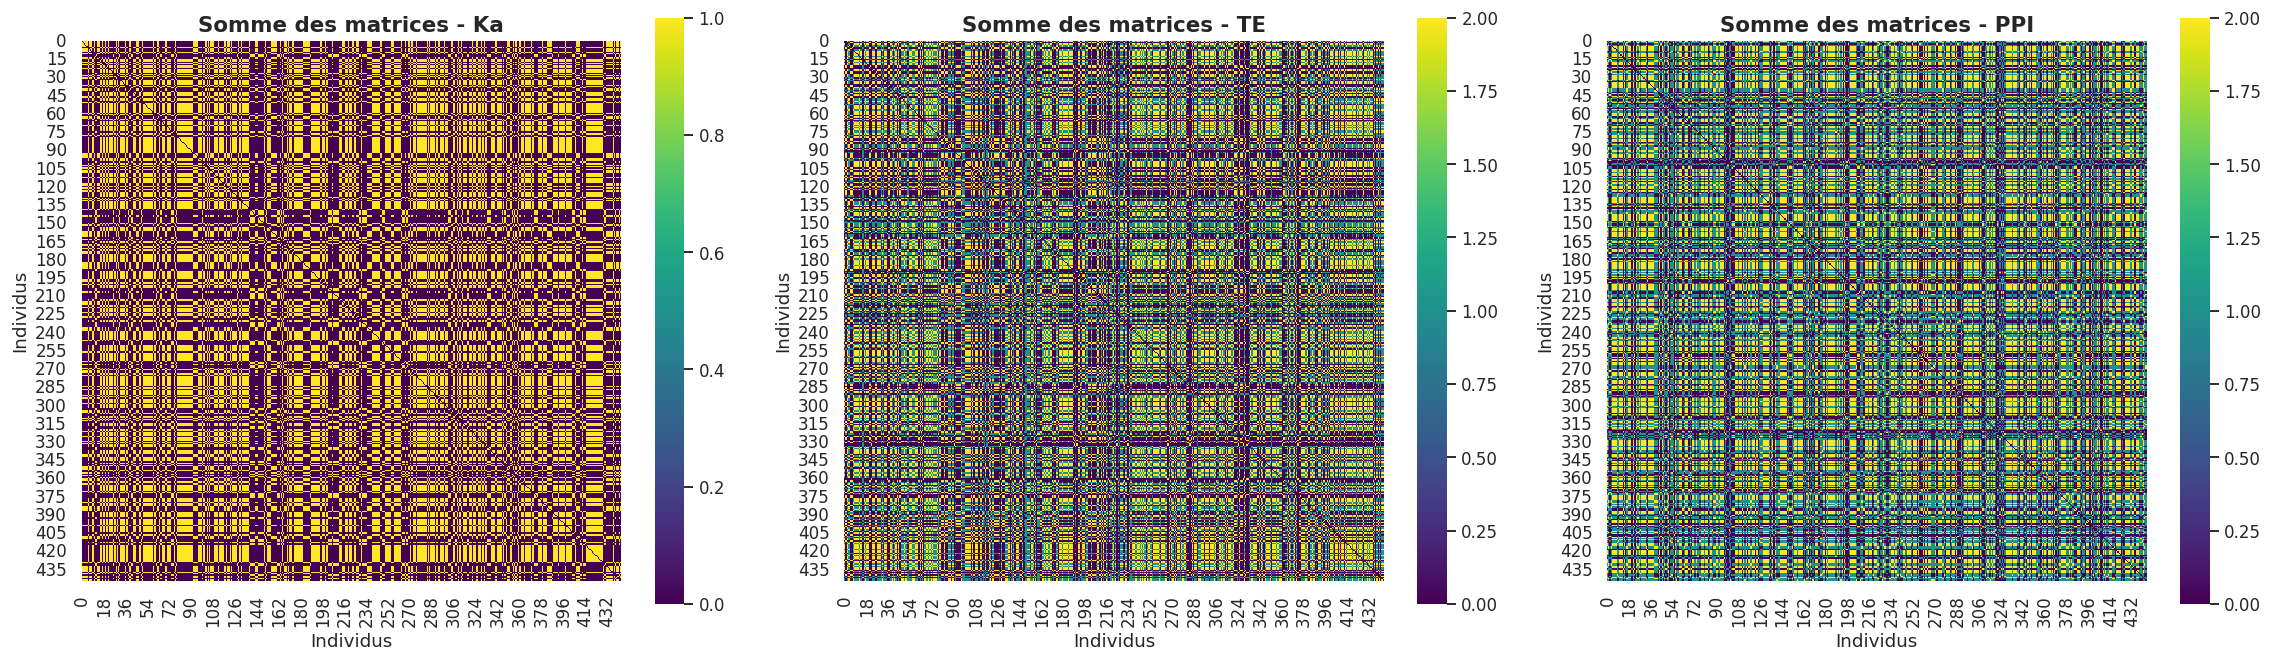

In [40]:
# Récupération des 5 meilleurs descripteurs selon la LDA
top_5_descriptors_lda = coef_df_sorted.head(5).index.tolist()

print("5 meilleurs descripteurs selon la LDA :")
print(top_5_descriptors_lda)

# Somme des matrices uniquement pour les top 5 descripteurs LDA
group_adjacency_matrices_lda = {}

for family_name, descriptors in family_groups.items():

    selected_descriptors = [
        descriptor
        for descriptor in descriptors
        if descriptor in top_5_descriptors_lda
        and descriptor in family_adjacency_matrices
    ]

    if not selected_descriptors:
        continue

    summed_matrix = np.sum(
        [
            family_adjacency_matrices[descriptor]
            for descriptor in selected_descriptors
        ],
        axis=0
    )

    group_adjacency_matrices_lda[family_name] = summed_matrix

    print(f"\nFamille : {family_name}")
    print(f"Descripteurs utilisés : {selected_descriptors}")
    print(f"Forme : {summed_matrix.shape}")
    print(f"Somme des valeurs : {summed_matrix.sum():.0f}")

# Visualisation des matrices sommées
fig, axes = plt.subplots(
    1,
    len(group_adjacency_matrices_lda),
    figsize=(7 * len(group_adjacency_matrices_lda), 6)
)

if len(group_adjacency_matrices_lda) == 1:
    axes = [axes]

for ax, (family_name, matrix) in zip(
    axes,
    group_adjacency_matrices_lda.items()
):
    sns.heatmap(
        matrix,
        ax=ax,
        cmap="viridis",
        square=True,
        cbar=True
    )

    ax.set_title(
        f"Somme des matrices - {family_name}",
        fontsize=14,
        fontweight="bold"
    )
    ax.set_xlabel("Individus")
    ax.set_ylabel("Individus")

plt.tight_layout()
plt.show()

In [41]:
# Compter le nombre de paires ayant une valeur 0, 1 ou 2
# dans chaque matrice agrégée par famille

for family_name, matrix in group_adjacency_matrices.items():
    matrix = np.asarray(matrix)

    print(f"\nFamille : {family_name}")

    for value in [0, 1, 2]:
        count_pairs = np.sum(matrix == value) / 2
        print(
            f"Nombre de paires avec la valeur {value} : "
            f"{int(count_pairs):,}"
        )


Famille : Ka
Nombre de paires avec la valeur 0 : 60,215
Nombre de paires avec la valeur 1 : 38,353
Nombre de paires avec la valeur 2 : 0

Famille : TE
Nombre de paires avec la valeur 0 : 45,113
Nombre de paires avec la valeur 1 : 28,233
Nombre de paires avec la valeur 2 : 25,222

Famille : PPI
Nombre de paires avec la valeur 0 : 33,591
Nombre de paires avec la valeur 1 : 41,115
Nombre de paires avec la valeur 2 : 23,862


In [43]:
import numpy as np

# Récupération des matrices agrégées par famille
matrix_ka = np.asarray(group_adjacency_matrices["Ka"])
matrix_te = np.asarray(group_adjacency_matrices["TE"])
matrix_ppi = np.asarray(group_adjacency_matrices["PPI"])

# Vérification des dimensions
assert matrix_ka.shape == matrix_te.shape == matrix_ppi.shape

# Sommes deux à deux
aggregation_pairwise = {
    "Ka_TE": matrix_ka + matrix_te,
    "TE_PPI": matrix_te + matrix_ppi,
    "Ka_PPI": matrix_ka + matrix_ppi,
}

# Somme des trois familles
aggregation_all = matrix_ka + matrix_te + matrix_ppi

# Affichage des résultats
for name, matrix in aggregation_pairwise.items():
    print(f"{name} : forme {matrix.shape}")
    print(matrix)


Ka_TE : forme (444, 444)
[[0 1 3 ... 1 1 2]
 [1 0 1 ... 2 0 1]
 [3 1 0 ... 1 1 2]
 ...
 [1 2 1 ... 0 0 1]
 [1 0 1 ... 0 0 2]
 [2 1 2 ... 1 2 0]]
TE_PPI : forme (444, 444)
[[0 1 2 ... 2 2 2]
 [1 0 1 ... 2 2 1]
 [2 1 0 ... 0 2 1]
 ...
 [2 2 0 ... 0 1 1]
 [2 2 2 ... 1 0 3]
 [2 1 1 ... 1 3 0]]
Ka_PPI : forme (444, 444)
[[0 2 1 ... 3 1 2]
 [2 0 2 ... 2 2 2]
 [1 2 0 ... 1 1 1]
 ...
 [3 2 1 ... 0 1 2]
 [1 2 1 ... 1 0 1]
 [2 2 1 ... 2 1 0]]


In [44]:
# Compter les valeurs de 0 à 4 dans chaque matrice pairwise

for matrix_name, matrix in aggregation_pairwise.items():
    matrix = np.asarray(matrix)

    print(f"\nMatrice : {matrix_name}")

    for value in range(5):
        count_pairs = np.sum(matrix == value) / 2

        print(
            f"Valeur {value} : "
            f"{int(count_pairs):,} paires"
        )


Matrice : Ka_TE
Valeur 0 : 27,358 paires
Valeur 1 : 35,361 paires
Valeur 2 : 25,878 paires
Valeur 3 : 9,971 paires
Valeur 4 : 0 paires

Matrice : TE_PPI
Valeur 0 : 15,218 paires
Valeur 1 : 27,849 paires
Valeur 2 : 32,597 paires
Valeur 3 : 17,143 paires
Valeur 4 : 5,761 paires

Matrice : Ka_PPI
Valeur 0 : 19,927 paires
Valeur 1 : 38,973 paires
Valeur 2 : 30,785 paires
Valeur 3 : 8,883 paires
Valeur 4 : 0 paires


### Matrice d'adjacence pour k_BIC

In [82]:
# Récupérer la matrice d'adjacence pour les clusters K-means par famille de descripteurs
family_adjacency_matrices_bic = {}

for family_name in X_top_5_scaled.columns:

    if (family_name== 'Ka'):
        optimal_k_bic = 3
    elif (family_name == 'TE_Density_Asymmetry'):
        optimal_k_bic = 4
    elif (family_name == 'TE_Number_Asymmetry'):
        optimal_k_bic = 10
    else: # PPI_Union & PPI_Jaccard
        optimal_k_bic = 5

    X_family = X_top_5_scaled[[family_name]]
    kmeans_family_bic = KMeans(n_clusters=optimal_k_bic, n_init=n_init, random_state=random_state, init='k-means++')
    labels_family_bic = kmeans_family_bic.fit_predict(X_family)
    
    Z_family_bic = pd.DataFrame(X_family, columns=X_family.columns)
    Z_family_bic['Cluster'] = labels_family_bic
    
    Z_family_binary_bic = pd.get_dummies(Z_family_bic['Cluster'], prefix='Cluster').astype(int)
    
    adjacency_matrix_family_bic = Z_family_binary_bic.values @ Z_family_binary_bic.values.T
    adjacency_matrix_family_bic = adjacency_matrix_family_bic - np.diag(np.diag(adjacency_matrix_family_bic))  # Soustraire les éléments diagonaux
    family_adjacency_matrices_bic[family_name] = adjacency_matrix_family_bic
    
    print(f"\nMatrice d'adjacence BIC pour la famille '{family_name}':")
    print(f"Shape: {adjacency_matrix_family_bic.shape}")
    print(f"Nombre de paires dans le même cluster: {(adjacency_matrix_family_bic.sum()/2):.0f}")
    # Diviser par 2 pour ne pas compter les paires (i,j) et (j,i)


Matrice d'adjacence BIC pour la famille 'Ka':
Shape: (444, 444)
Nombre de paires dans le même cluster: 38353

Matrice d'adjacence BIC pour la famille 'TE_Number_Asymmetry':
Shape: (444, 444)
Nombre de paires dans le même cluster: 23516

Matrice d'adjacence BIC pour la famille 'TE_Density_Asymmetry':
Shape: (444, 444)
Nombre de paires dans le même cluster: 30256

Matrice d'adjacence BIC pour la famille 'PPI_Union':
Shape: (444, 444)
Nombre de paires dans le même cluster: 43286

Matrice d'adjacence BIC pour la famille 'PPI_Jaccard':
Shape: (444, 444)
Nombre de paires dans le même cluster: 37935


In [83]:
# Sauvegarder les matrices d'adjacence dans un fichier CSV
for family_name, adjacency_matrix in family_adjacency_matrices_bic.items():
    adjacency_df = pd.DataFrame(adjacency_matrix, index=X_top_5_scaled.index, columns=X_top_5_scaled.index)
    adjacency_df.to_csv(f'Données/adjacency/lda/adjacency_matrix_bic_{family_name}.csv')
    print(f"Matrice d'adjacence BIC pour la famille '{family_name}' sauvegardée dans 'Données/adjacency/lda/adjacency_matrix_bic_{family_name}.csv'")

Matrice d'adjacence BIC pour la famille 'Ka' sauvegardée dans 'Données/adjacency/lda/adjacency_matrix_bic_Ka.csv'
Matrice d'adjacence BIC pour la famille 'TE_Number_Asymmetry' sauvegardée dans 'Données/adjacency/lda/adjacency_matrix_bic_TE_Number_Asymmetry.csv'
Matrice d'adjacence BIC pour la famille 'TE_Density_Asymmetry' sauvegardée dans 'Données/adjacency/lda/adjacency_matrix_bic_TE_Density_Asymmetry.csv'
Matrice d'adjacence BIC pour la famille 'PPI_Union' sauvegardée dans 'Données/adjacency/lda/adjacency_matrix_bic_PPI_Union.csv'
Matrice d'adjacence BIC pour la famille 'PPI_Jaccard' sauvegardée dans 'Données/adjacency/lda/adjacency_matrix_bic_PPI_Jaccard.csv'


In [84]:
# --- Calcul des tailles ET ratios redondant/divergent par cluster ---
max_k = max(10, 5, 3, 4)
columns = [f'Cluster {i}' for i in range(max_k)]

cluster_comparison_bic = pd.DataFrame(index=X_top_5_scaled.columns, columns=columns, dtype=float)
ratio_comparison_bic   = pd.DataFrame(index=X_top_5_scaled.columns, columns=columns, dtype=float)

y_train = pd.read_csv("Données/Y_train_clean.csv")
classifications = y_train['Classification'].values  # 0=redondant, 1=divergent

for family_name in X_top_5_scaled.columns:
    # Recalculer les clusters pour cette famille spécifique
    if (family_name== 'Ka'):
        optimal_k_bic = 3
    elif (family_name == 'TE_Density_Asymmetry'):
        optimal_k_bic = 4
    elif (family_name == 'TE_Number_Asymmetry'):
        optimal_k_bic = 10
    else: # PPI_Union & PPI_Jaccard
        optimal_k_bic = 5

    X_family = X_top_5_scaled[[family_name]]
    kmeans_family_bic = KMeans(n_clusters=optimal_k_bic, n_init=n_init, random_state=random_state, init='k-means++')
    labels_family_bic = kmeans_family_bic.fit_predict(X_family)

    # Calculer taille et ratio pour chaque cluster
    cluster_sizes  = []
    cluster_ratios = []
    for cluster_id in range(optimal_k_bic):
        mask_cluster = labels_family_bic == cluster_id
        n = int(np.sum(mask_cluster))
        n_div = int(np.sum(classifications[mask_cluster] == 1))
        n_red = n - n_div
        ratio = n_red / n_div if n_div > 0 else np.inf  # redondant/divergent
        cluster_sizes.append(n)
        cluster_ratios.append(ratio)

    # Trier les deux listes ensemble par taille décroissante
    sorted_pairs = sorted(zip(cluster_sizes, cluster_ratios), key=lambda x: x[0], reverse=True)

    for rank, (size, ratio) in enumerate(sorted_pairs):
        cluster_comparison_bic.loc[family_name, f'Cluster {rank}'] = size
        ratio_comparison_bic.loc[family_name,   f'Cluster {rank}'] = ratio

# --- Construction des annotations combinées ---
# Chaque cellule affiche : "N pts\nR:D = x.xx"
annot_matrix_bic = pd.DataFrame(index=cluster_comparison_bic.index, columns=cluster_comparison_bic.columns, dtype=object)
nan_mask_bic = cluster_comparison_bic.isna()

for fam in cluster_comparison_bic.index:
    for col in cluster_comparison_bic.columns:
        if nan_mask_bic.loc[fam, col]:
            annot_matrix_bic.loc[fam, col] = ""
        else:
            n     = int(cluster_comparison_bic.loc[fam, col])
            ratio = ratio_comparison_bic.loc[fam, col]
            ratio_str = f"{ratio:.2f}" if not np.isinf(ratio) else "∞"
            annot_matrix_bic.loc[fam, col] = f"{n} paires\nR/D={ratio_str}"

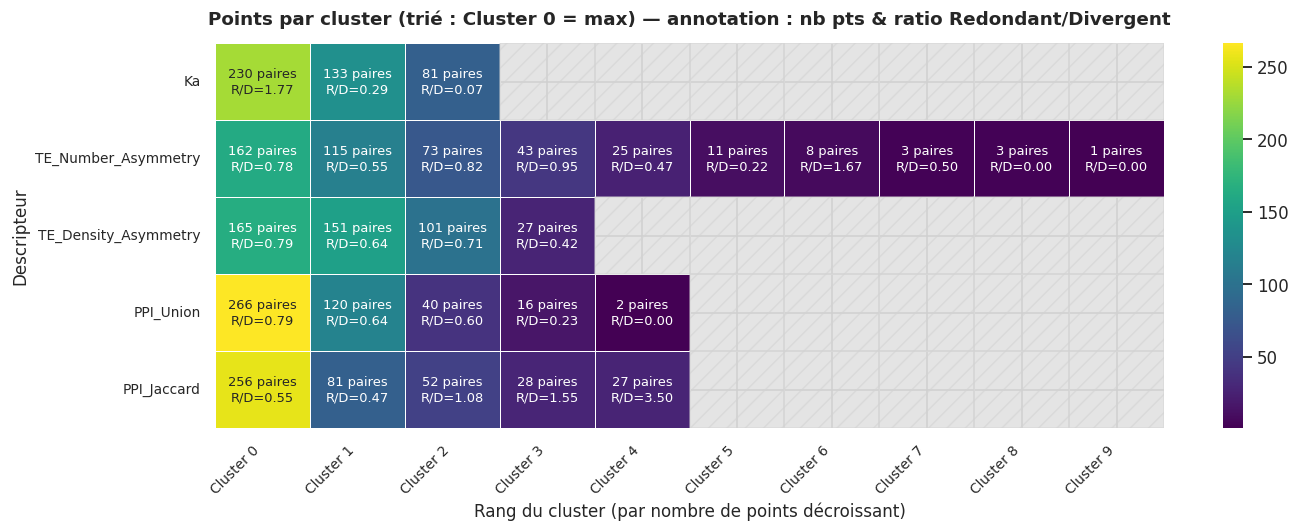

In [85]:
# --- Heatmap ---
fig, ax = plt.subplots(figsize=(13, 5))

sns.heatmap(
    cluster_comparison_bic.astype(float).values,
    annot=annot_matrix_bic.values,
    fmt="",                  # fmt vide car les annotations sont des strings
    cmap='viridis',
    cbar=True,
    mask=nan_mask_bic.values,
    linewidths=0.5,
    linecolor='white',
    ax=ax,
    annot_kws={"size": 8.5}
)

for i in range(cluster_comparison_bic.shape[0]):
    for j in range(cluster_comparison_bic.shape[1]):
        if nan_mask_bic.iloc[i, j]:
            ax.add_patch(plt.Rectangle(
                (j, i), 1, 1,
                fill=True, color='lightgrey', hatch='//', alpha=0.6
            ))

ax.set_title(
    'Points par cluster (trié : Cluster 0 = max) — annotation : nb pts & ratio Redondant/Divergent',
    fontsize=12, fontweight='bold', pad=12
)
ax.set_xlabel('Rang du cluster (par nombre de points décroissant)', fontsize=11)
ax.set_ylabel('Descripteur', fontsize=11)
ax.set_yticks(np.arange(cluster_comparison_bic.shape[0]) + 0.5)
ax.set_yticklabels(cluster_comparison_bic.index, rotation=0, fontsize=9)
ax.set_xticks(np.arange(cluster_comparison_bic.shape[1]) + 0.5)
ax.set_xticklabels(cluster_comparison_bic.columns, rotation=45, ha='right', fontsize=9)
plt.tight_layout()
plt.savefig('Plots/kmeans/lda/cluster_comparison_bic_ratio_heatmap_5.png', dpi=300)
plt.show()

In [86]:
# Additionner les matrices d'adjacence de toutes les descripteurs et compter les nombres dans la matrice résultante
total_adjacency_sum_bic = np.zeros_like(list(family_adjacency_matrices_bic.values())[0])
for adjacency_matrix in family_adjacency_matrices_bic.values():
    total_adjacency_sum_bic += adjacency_matrix

num_zeros_bic = (np.sum(total_adjacency_sum_bic == 0)  - 444 )/ 2 # Nombre de paires de points dans le même cluster pour exactement 0 descripteurs
num_ones_bic = np.sum(total_adjacency_sum_bic == 1) / 2 # Nombre de paires de points dans le même cluster pour exactement 1 descripteur
num_twos_bic = np.sum(total_adjacency_sum_bic == 2) / 2 # Nombre de paires de points dans le même cluster pour exactement 2 descripteurs
num_threes_bic = np.sum(total_adjacency_sum_bic == 3) / 2 # Nombre de paires de points dans le même cluster pour exactement 3 descripteurs
num_fours_bic = np.sum(total_adjacency_sum_bic == 4) / 2 # Nombre de paires de points dans le même cluster pour exactement 4 descripteurs
num_fives_bic = np.sum(total_adjacency_sum_bic == 5) / 2 # Nombre de paires de points dans le même cluster pour exactement 5 descripteurs

print(f"Nombre de paires de points dans le même cluster pour exactement 0 descripteurs: {num_zeros_bic:.0f}")
print(f"Nombre de paires de points dans le même cluster pour exactement 1 descripteur: {num_ones_bic:.0f}")
print(f"\nNombre de paires de points dans le même cluster pour exactement 2 descripteurs: {num_twos_bic:.0f}")
print(f"Nombre de paires de points dans le même cluster pour exactement 3 descripteurs: {num_threes_bic:.0f}")
print(f"Nombre de paires de points dans le même cluster pour exactement 4 descripteurs: {num_fours_bic:.0f}")
print(f"Nombre de paires de points dans le même cluster pour exactement 5 descripteurs: {num_fives_bic:.0f}")

Nombre de paires de points dans le même cluster pour exactement 0 descripteurs: 15327
Nombre de paires de points dans le même cluster pour exactement 1 descripteur: 28440

Nombre de paires de points dans le même cluster pour exactement 2 descripteurs: 28815
Nombre de paires de points dans le même cluster pour exactement 3 descripteurs: 17335
Nombre de paires de points dans le même cluster pour exactement 4 descripteurs: 6874
Nombre de paires de points dans le même cluster pour exactement 5 descripteurs: 1555


In [87]:
print("\nDistribution des valeurs dans la matrice BIC:")
total_count_bic = 0
total_pairs_bic = (total_adjacency_sum_bic.size - 444) / 2

for v in range(6):
    if v == 0:
        count_bic = np.sum(total_adjacency_sum_bic == v) - 444
        count_bic = count_bic / 2
    else:
        count_bic = np.sum(total_adjacency_sum_bic == v) / 2

    pct = 100 * count_bic / total_pairs_bic
    print(f"  Valeur {v} : {int(count_bic):,} paires ({pct:.1f}%)")
    total_count_bic += count_bic



Distribution des valeurs dans la matrice BIC:
  Valeur 0 : 15,327 paires (15.6%)
  Valeur 1 : 28,440 paires (28.9%)
  Valeur 2 : 28,815 paires (29.3%)
  Valeur 3 : 17,335 paires (17.6%)
  Valeur 4 : 6,874 paires (7.0%)
  Valeur 5 : 1,555 paires (1.6%)


## K-means sur composantes t-SNE

### Calcul des composantes t-SNE

In [88]:
# Calculer les composantes t-SNE pour les descripteurs de X_top_5_scaled
tsne_results = {}

print("Calcul des composantes t-SNE pour chaque famille...")
print("-" * 70)

for family_name in X_top_5_scaled.columns:
    X_family = X_top_5_scaled[family_name]
    
    # Appliquer t-SNE (2 composantes)
    tsne = TSNE(n_components=2, random_state=random_state, init = 'random', perplexity=30, max_iter=1000, learning_rate= 'auto')
    X_family = X_top_5_scaled[[family_name]]
    X_tsne = tsne.fit_transform(X_family)
    
    tsne_results[family_name] = pd.DataFrame(
        X_tsne, 
        columns=['TSNE1', 'TSNE2']
    )
    
    print(f" {family_name}: {X_tsne.shape} ({len(X_family.columns)} descripteurs originaux → 2 composantes)")

print("-" * 70)
print(f"\nAperçu des composantes t-SNE pour la première famille:")
first_family = list(tsne_results.keys())[0]
print(tsne_results[first_family].head())

Calcul des composantes t-SNE pour chaque famille...
----------------------------------------------------------------------
 Ka: (444, 2) (1 descripteurs originaux → 2 composantes)
 TE_Number_Asymmetry: (444, 2) (1 descripteurs originaux → 2 composantes)
 TE_Density_Asymmetry: (444, 2) (1 descripteurs originaux → 2 composantes)
 PPI_Union: (444, 2) (1 descripteurs originaux → 2 composantes)
 PPI_Jaccard: (444, 2) (1 descripteurs originaux → 2 composantes)
----------------------------------------------------------------------

Aperçu des composantes t-SNE pour la première famille:
       TSNE1      TSNE2
0  -7.139992 -15.726526
1  -6.414856 -16.117290
2   1.579834 -18.404476
3 -11.702740 -12.621398
4  -6.615835 -16.013083


In [89]:
# Exécuter K-means sur les composantes t-SNE
kmeans_results_tsne = {}

print("Exécution du K-means sur les composantes t-SNE de chaque famille...")
print("-" * 70)

for family_name, tsne_data in tsne_results.items():
    # Dictionnaire pour stocker les métriques pour cette famille
    family_results_tsne = {
        'inertia': [],
        'silhouette': [],
        'davies_bouldin': [],
        'calinski_harabasz': [],
        'models': [],
        'labels': {}
    }
    
    if (family_name== 'Pfam'):
        optimal_k_visua_direct = 5
    elif family_name == 'PPI':
        optimal_k_visua_direct = 5
    elif family_name == 'Ks_et_Ka':
        optimal_k_visua_direct = 2
    else:
        optimal_k_visua_direct = 3

    kmeans = KMeans(n_clusters=optimal_k_visua_direct, n_init=n_init, random_state=random_state, init='k-means++')
    labels = kmeans.fit_predict(tsne_data.values)
    
    # Calculer les métriques
    inertia = kmeans.inertia_
    silhouette = silhouette_score(tsne_data.values, labels) if len(np.unique(labels)) > 1 else np.nan
    davies_bouldin = davies_bouldin_score(tsne_data.values, labels) if len(np.unique(labels)) > 1 else np.nan
    calinski_harabasz = calinski_harabasz_score(tsne_data.values, labels) if len(np.unique(labels)) > 1 else np.nan
    
    family_results_tsne['inertia'].append(inertia)
    family_results_tsne['silhouette'].append(silhouette)
    family_results_tsne['davies_bouldin'].append(davies_bouldin)
    family_results_tsne['calinski_harabasz'].append(calinski_harabasz)
    family_results_tsne['models'].append(kmeans)
    family_results_tsne['labels'] = labels
    
    kmeans_results_tsne[family_name] = family_results_tsne
    print(f" {family_name}: K-means avec t-SNE testé")

print("-" * 70)

Exécution du K-means sur les composantes t-SNE de chaque famille...
----------------------------------------------------------------------
 Ka: K-means avec t-SNE testé
 TE_Number_Asymmetry: K-means avec t-SNE testé
 TE_Density_Asymmetry: K-means avec t-SNE testé
 PPI_Union: K-means avec t-SNE testé
 PPI_Jaccard: K-means avec t-SNE testé
----------------------------------------------------------------------


### Visualisation spatiale des clusters t-SNE

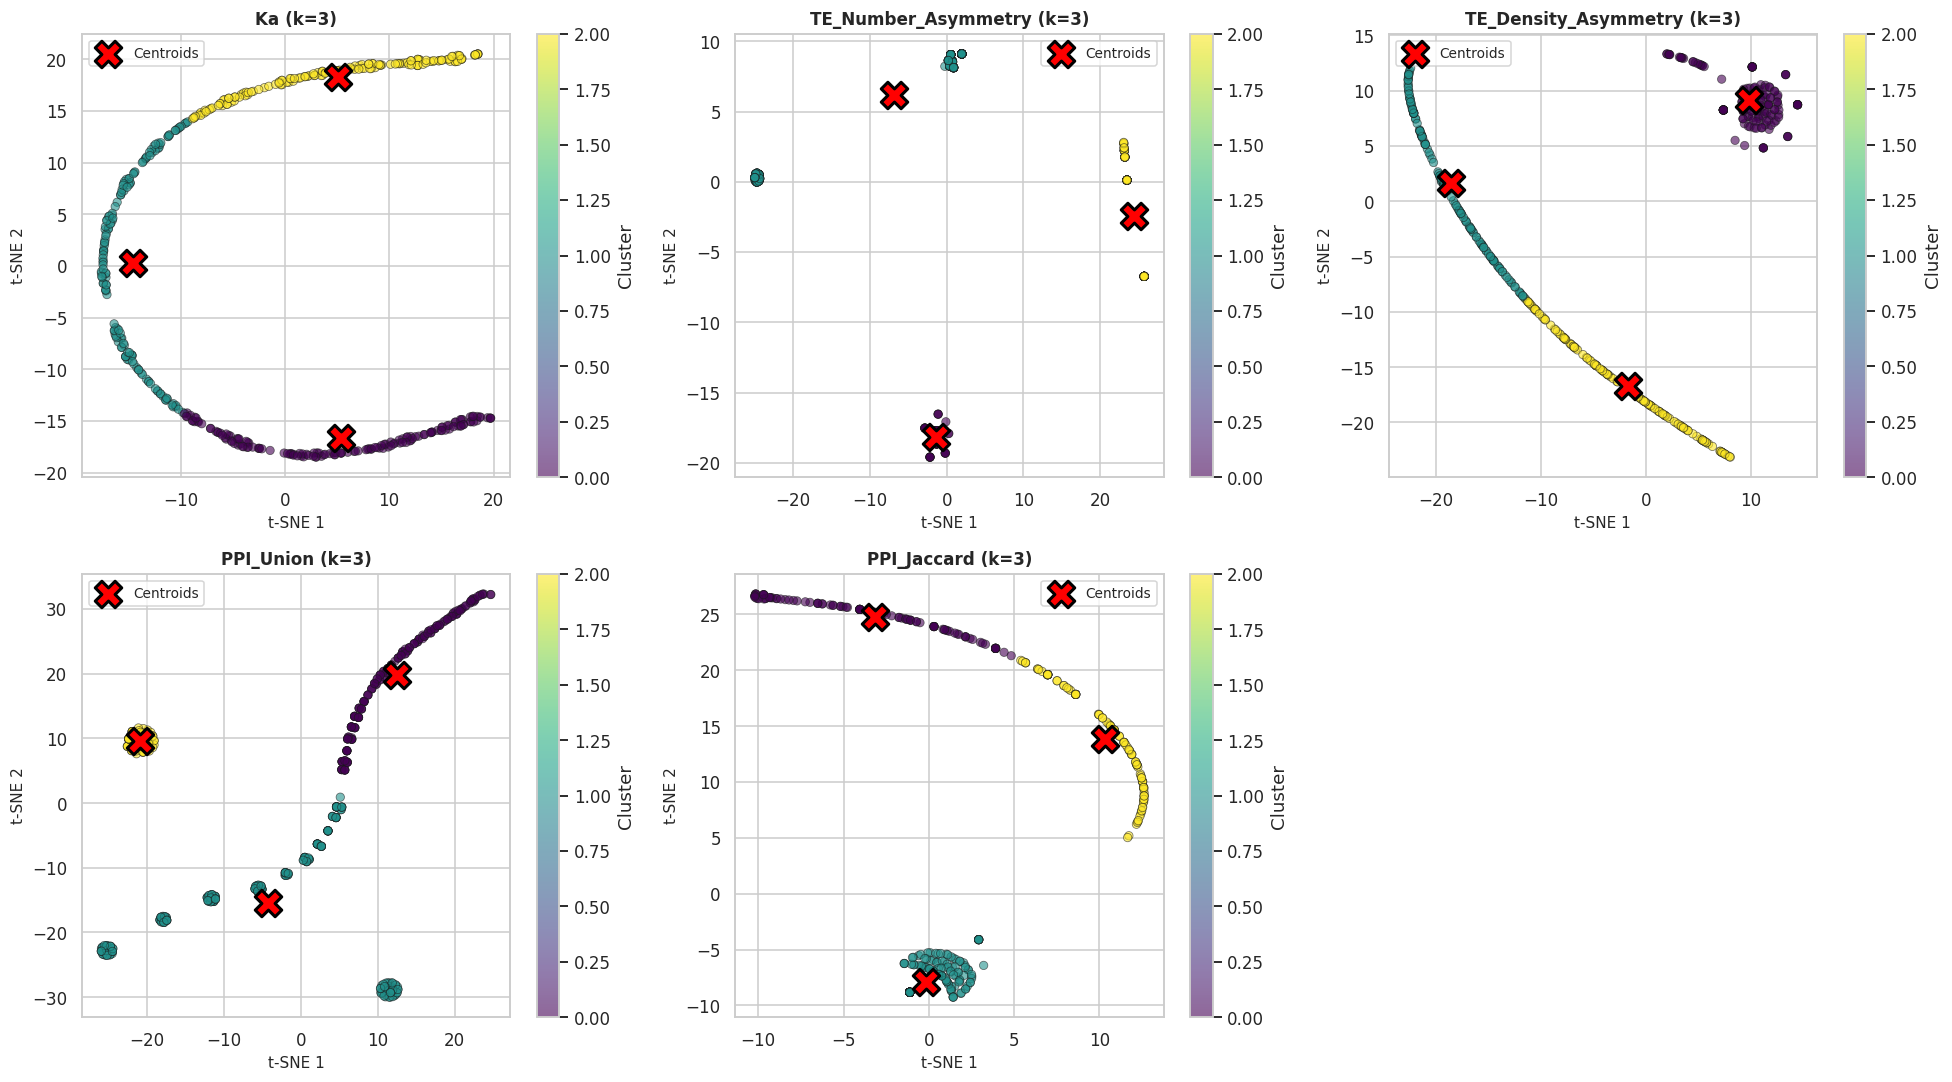

In [90]:
# Visualiser les clusters t-SNE pour k=3
n_families = 5
n_cols = 3
n_rows = (n_families + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5*n_rows))
axes = axes.flatten()

for idx, (family_name, tsne_data) in enumerate(tsne_results.items()):
    if (family_name== 'Pfam'):
        k_family = 5
    elif family_name == 'PPI':
        k_family = 5
    elif family_name == 'Ks_et_Ka':
        k_family = 2
    else :
        k_family = 3
    ax = axes[idx]
    labels = kmeans_results_tsne[family_name]['labels']
    
    scatter = ax.scatter(
        tsne_data['TSNE1'], tsne_data['TSNE2'],
        c=labels, cmap='viridis', s=30, alpha=0.6, edgecolors='k', linewidths=0.5
    )
    
    # Ajouter les centroïdes (utiliser le modèle disponible dans kmeans_results_tsne)
    kmeans_models = kmeans_results_tsne[family_name].get('models', [])
    if len(kmeans_models) > 0:
        kmeans_model = kmeans_models[0]
        centroids = kmeans_model.cluster_centers_
        ax.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=300, 
                   edgecolors='black', linewidths=2, label='Centroids')
    
    ax.set_xlabel(f't-SNE 1', fontsize=10)
    ax.set_ylabel(f't-SNE 2', fontsize=10)
    ax.set_title(f'{family_name} (k={k_family})', fontsize=11, fontweight='bold')
    ax.legend(fontsize=9)
    plt.colorbar(scatter, ax=ax, label='Cluster')

# Masquer les axes inutilisés
for idx in range(n_families, len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
# plt.savefig('Plots/kmeans/family/tsne_clusters_comparison_ppi_5.png', dpi=300)
plt.show()